# Лекция 5: Оптимизаторы — от SGD до Adam

**Что разберём:**

1. **Зачем оптимизатор.** Градиент говорит *куда* идти, но не говорит *каким шагом*. Все оптимизаторы — это способы превратить градиент в разумный шаг $\Delta\theta$.
2. **SGD** — база, от которой всё отсчитывается. Игрушечная картинка «катимся шариком вниз по оврагу».
3. **Momentum / Nesterov** — добавляем инерцию: «сохраняем направление движения, как будто катимся по извилистой дороге».
4. **Adagrad / RMSprop** — у каждого параметра свой шаг, свой «регулятор чувствительности».
5. **Adam / AdamW** — momentum + адаптивность + честный weight decay. Сегодня дефолт в 90% задач.
6. **Новые оптимизаторы:** Nadam, RAdam, LAMB, Adafactor, Lion, Sophia — кто они и когда нужны.
7. **Практика в PyTorch:** `torch.optim`, `state_dict`, общие рецепты подбора `lr`, `weight_decay`.
8. **Эксперименты:** все оптимизаторы бегут по одной функции потерь и по одной реальной нейросети.

**Идея лекции.** В лекциях 2–4 мы разобрали *как считать градиент* `loss.backward()`. Оптимизатор — это последний, но самый недооценённый шаг: он решает, **как именно** использовать этот градиент. При одном и том же градиенте разные оптимизаторы могут сойтись в 10 раз быстрее — или не сойтись вовсе.

> Все формулы пишем «с нуля» и **проверяем численно** на маленьких двумерных функциях, которые можно нарисовать глазами. Это лучший способ почувствовать, что делает параметр `beta1`, `beta2`, `eps` и почему Adam такой популярный.

**Обозначения (сквозные на всю лекцию):**

| Символ | Смысл |
|---|---|
| $\theta$ | вектор всех параметров модели (веса и bias) |
| $g_t = \nabla_\theta J(\theta_t)$ | градиент loss в момент шага $t$ |
| $\eta$ | learning rate (скорость обучения) |
| $v_t, m_t, s_t$ | внутренние буферы оптимизатора (velocity, моменты) |
| $\beta_1, \beta_2$ | коэффициенты «памяти» (обычно $0.9$, $0.999$) |
| $\varepsilon$ | маленькая константа для деления (обычно $10^{-8}$) |
| $\Delta\theta$ | шаг, который оптимизатор применяет к параметрам |

Главная формула, из которой растёт **вообще всё**:

$$\boxed{\ \theta_{t+1} = \theta_t - \eta\,\Delta\theta_t\ }$$

Разные оптимизаторы — это разные способы посчитать $\Delta\theta_t$ из истории градиентов $g_1, g_2, \dots, g_t$.

## Карта лекции

```text
                         градиент g_t = ∇J(θ)
                                 │
        ┌────────────────────────┼─────────────────────────┐
        │                        │                         │
   «куда идти»              «каким шагом»              «с какой
   направление             адаптивность               инерцией»
        │                        │                         │
        ▼                        ▼                         ▼
   SGD ──► Momentum ──► Nesterov        Adagrad ──► RMSprop        Adam ──► AdamW
        (инерция)      (взгляд вперёд)  (свой шаг               (инерция + адаптивность
                                        каждому w)              + честный weight decay)
        └────────────────────────────── Adam ──────────────────────────────┘
                                       │
                    Nadam / RAdam / LAMB / Adafactor / Lion / Sophia
                              (современные вариации)
```

Сначала — словами и картинками, потом — кодом, в конце — на настоящей нейросети.

## Шпаргалка: все оптимизаторы одной фразой

Прежде чем нырять в формулы, запомните интуицию. К каждой метафоре мы вернёмся с кодом и картинкой.

| Оптимизатор | Идея одной фразой | Аналогия |
|---|---|---|
| **GD** | шаг по градиенту по всей выборке | идём с идеальной картой местности, но карту пересчитываем целиком |
| **SGD** | шаг по градиенту одного примера/батча | идём наощупь с фонариком: шумно, но быстро |
| **SGD + Momentum** | «помним», куда ехали | **катимся по извилистой дороге — сохраняем направление движения**, как тяжёлый шар |
| **Nesterov** | сначала заглядываем вперёд, потом тормозим | опытный лыжник смотрит на поворот заранее, а не под ноги |
| **Adagrad** | у каждого веса свой шаг; кто много бегал — шагает мельче | у каждого бегуна свой запас сил: уставший замедляется |
| **RMSprop** | то же, но помним только недавнюю историю | забываем старое, чтобы не застрять навсегда |
| **Adam** | momentum + адаптивность + разогрев | у каждого веса свой водитель с круиз-контролем и персональным тормозом |
| **AdamW** | Adam, но weight decay вычтен честно | то же, но штраф за вес списывают отдельно, а не прячут в градиент |
| **Adadelta** | Adagrad без выбора learning rate | «сам поймёт, каким шагом идти» |
| **Nadam** | Adam + взгляд вперёд от Нестерова | водитель, который смотрит на два поворота вперёд |
| **RAdam** | Adam с тёплым стартом | не даём газа, пока не прогрели двигатель |
| **LAMB** | Adam, выравнивающий шаг по слоям | раздаём всем слоям одинаковый бюджет шага, а не «кто громче» |
| **Lion** | шаг берётся от **знака** момента, а не от его величины | идём «в ту сторону», не важно, насколько сильно тянет |
| **Sophia** | Adam со вторым порядком (оценка кривизны) | едем быстрее там, где дорога прямая, и тормозим на поворотах |

---
# Часть 0. Инструменты: двумерные ландшафты, которые видно глазами

Оптимизатор — многомерная штука, но всё его поведение прекрасно видно на **двумерной** функции потерь $f(w_1, w_2)$, которую можно нарисовать изолиниями. Мы будем гонять по ней все оптимизаторы и смотреть на траектории.

Рабочая лошадка — «овраг» (квадратичная форма с разным масштабом по осям):

$$f(w_1,w_2) = \tfrac12\bigl(w_1^2 + \kappa\, w_2^2\bigr),\qquad \nabla f = (w_1,\ \kappa w_2)$$

- при $\kappa=3$ овраг пологий, при $\kappa=25$ — глубокий и узкий;
- минимум всегда в $(0,0)$;
- чем больше $\kappa$, тем сильнее SGD «метается» поперёк оврага — и тем заметнее выигрыш от momentum и Adam.

Символ $\kappa$ («число обусловленности») — главный враг SGD: отношение максимальной и минимальной кривизны.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from IPython.display import HTML, Image
import ipywidgets as widgets
from ipywidgets import interact
from io import BytesIO

device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

plt.rcParams['figure.dpi'] = 110
plt.rcParams['animation.embed_limit'] = 40  # MB, чтобы анимации влезли в ноутбук

print('torch', torch.__version__, '| device:', device)
print('Все ландшафты ниже можно нарисовать глазами: f(w1, w2).')

torch 2.2.0.dev20230914+cu121 | device: cuda
Все ландшафты ниже можно нарисовать глазами: f(w1, w2).


In [2]:
# ---------- общие инструменты: ландшафты, траектории, анимация ----------

def bowl(w, kappa=3.0):
    'Овраг: параболоид с разной кривизной по осям. Минимум в (0, 0).'
    return 0.5 * (w[..., 0] ** 2 + kappa * w[..., 1] ** 2)

def grad_bowl(w, kappa=3.0):
    return np.stack([w[..., 0], kappa * w[..., 1]], axis=-1)

def grid(f, xlim, ylim, n=240, **kw):
    'Сетка значений функции для рисования изолиний.'
    xs = np.linspace(*xlim, n)
    ys = np.linspace(*ylim, n)
    XX, YY = np.meshgrid(xs, ys)
    ZZ = f(np.stack([XX, YY], axis=-1), **kw)
    return XX, YY, ZZ

def draw_contours(ax, f, xlim, ylim, nlev=30, **kw):
    XX, YY, ZZ = grid(f, xlim, ylim, **kw)
    cs = ax.contour(XX, YY, ZZ, levels=nlev, cmap='viridis', alpha=0.7)
    ax.set(xlim=xlim, ylim=ylim, xlabel='$w_1$', ylabel='$w_2$')
    return cs

import tempfile, os as _os

def show_anim(anim):
    'Показать анимацию прямо в ноутбуке — компактным GIF.'
    plt.close(anim._fig)
    fd, fname = tempfile.mkstemp(suffix='.gif')
    _os.close(fd)
    try:
        anim.save(fname, writer=animation.PillowWriter(fps=15), dpi=80)
        with open(fname, 'rb') as fh:
            data = fh.read()
    finally:
        _os.remove(fname)
    return Image(data=data, format='gif')

def path_anim(paths, f, xlim, ylim, labels=None, title='', interval=60, nlev=30):
    'Анимировать одну или несколько траекторий по общему ландшафту.'
    if isinstance(paths, np.ndarray):
        paths = [paths]
    paths = [np.asarray(p, dtype=float) for p in paths]
    if labels is None:
        labels = [None] * len(paths)
    colors = ['crimson', 'black', 'limegreen', 'royalblue', 'orange', 'purple']
    fig, ax = plt.subplots(figsize=(5.4, 5.4))
    draw_contours(ax, f, xlim, ylim, nlev=nlev)
    ax.set_title(title)
    lines, pts, ends = [], [], []
    nmax = max(len(p) for p in paths)
    for i, (p, lab) in enumerate(zip(paths, labels)):
        c = colors[i % len(colors)]
        ax.plot(p[:, 0], p[:, 1], color=c, lw=1, alpha=0.4, label=lab)
        ln, = ax.plot([], [], color=c, lw=2)
        pt, = ax.plot([], [], 'o', color=c, ms=7, markeredgecolor='k')
        ax.plot(p[0, 0], p[0, 1], '*', color='gold', ms=15, markeredgecolor='k', zorder=5)
        ax.plot(p[-1, 0], p[-1, 1], 'X', color=c, ms=11, markeredgecolor='k', zorder=5)
        lines.append(ln); pts.append(pt)
    if any(labels):
        ax.legend(loc='upper right', fontsize=8)
    def upd(i):
        for k, p in enumerate(paths):
            j = min(i, len(p) - 1)
            lines[k].set_data(p[:j + 1, 0], p[:j + 1, 1])
            pts[k].set_data([p[j, 0]], [p[j, 1]])
        return lines + pts
    anim = animation.FuncAnimation(fig, upd, frames=nmax, interval=interval, blit=True)
    return show_anim(anim)

print('Инструменты готовы: bowl(kappa) + path_anim().')

Инструменты готовы: bowl(kappa) + path_anim().


In [3]:
# ---------- единые (numpy) реализации всех оптимизаторов ----------
# Именно их мы будем гонять по ландшафтам и рисовать. В части 6 то же самое
# даст torch.optim - и мы сверим результаты.

def run_optimizer(name, grad, x0, steps=120, lr=0.1, **kw):
    '''Прогнать оптимизатор из точки x0 и вернуть траекторию (steps+1, dim).'''
    x = np.array(x0, dtype=float)
    v = np.zeros_like(x)   # momentum / первый момент
    s = np.zeros_like(x)   # второй момент / сумма квадратов
    m = np.zeros_like(x)
    path = [x.copy()]
    for t in range(1, steps + 1):
        g = grad(x)
        if name == 'sgd':
            x = x - lr * g

        elif name == 'momentum':
            b = kw.get('beta', 0.9)
            v = b * v + g
            x = x - lr * v

        elif name == 'nesterov':
            b = kw.get('beta', 0.9)
            v = b * v + g                  # как momentum
            d = g + b * v                  # «взгляд вперёд» (форма PyTorch)
            x = x - lr * d

        elif name == 'adagrad':
            s = s + g * g
            x = x - lr * g / (np.sqrt(s) + 1e-8)

        elif name == 'rmsprop':
            b = kw.get('beta', 0.9)
            s = b * s + (1 - b) * g * g
            x = x - lr * g / (np.sqrt(s) + 1e-8)

        elif name == 'adam':
            b1, b2 = kw.get('beta1', 0.9), kw.get('beta2', 0.999)
            m = b1 * m + (1 - b1) * g
            s = b2 * s + (1 - b2) * g * g
            m_hat = m / (1 - b1 ** t)     # поправка на смещение (bias correction)
            s_hat = s / (1 - b2 ** t)
            x = x - lr * m_hat / (np.sqrt(s_hat) + 1e-8)

        elif name == 'adamw':
            b1, b2, wd = kw.get('beta1', 0.9), kw.get('beta2', 0.999), kw.get('wd', 0.01)
            m = b1 * m + (1 - b1) * g
            s = b2 * s + (1 - b2) * g * g
            m_hat = m / (1 - b1 ** t)
            s_hat = s / (1 - b2 ** t)
            x = x - lr * (m_hat / (np.sqrt(s_hat) + 1e-8) + wd * x)

        elif name == 'nadam':
            b1, b2 = kw.get('beta1', 0.9), kw.get('beta2', 0.999)
            m = b1 * m + (1 - b1) * g
            s = b2 * s + (1 - b2) * g * g
            m_hat = m / (1 - b1 ** t)
            s_hat = s / (1 - b2 ** t)
            # «взгляд вперёд»: смесь текущего и следующего момента
            m_nad = (b1 * m_hat + (1 - b1) * g / (1 - b1 ** t))
            x = x - lr * m_nad / (np.sqrt(s_hat) + 1e-8)

        else:
            raise ValueError(name)
        path.append(x.copy())
    return np.array(path)

NAMES = ['sgd', 'momentum', 'nesterov', 'adagrad', 'rmsprop', 'adam', 'adamw']
print('Готовы оптимизаторы:', NAMES)

Готовы оптимизаторы: ['sgd', 'momentum', 'nesterov', 'adagrad', 'rmsprop', 'adam', 'adamw']


---
# Часть 1. База: градиентный спуск и SGD

## 1.1. Что вообще происходит

Самый простой спуск: **идём против градиента** маленькими шагами.

$$\theta_{t+1} = \theta_t - \eta\,\nabla_\theta J(\theta_t)$$

- **GD (full-batch)** считает градиент по **всей** выборке. Направление точное, но каждый шаг дорогой.
- **SGD** берёт один пример или мини-батч. Направление шумное, зато шагов в разы больше, и они дёшевы.

Именно шум — источник и проблем, и пользы SGD:

- шум заставляет шаги «дёргаться» (плохо для точной сходимости);
- тот же шум **выталкивает из плоских седловых точек и мелких локальных ям** (хорошо для обобщения).

Чуть позже мы увидим, что все остальные оптимизаторы — надстройки именно над этим простым правилом.

**Аналогия.** SGD — это спуск с фонариком: видим только пару метров вокруг, спускаемся наощупь, но зато быстро двигаемся. GD — идём с полной картой местности, зато пересчитывать её долго.

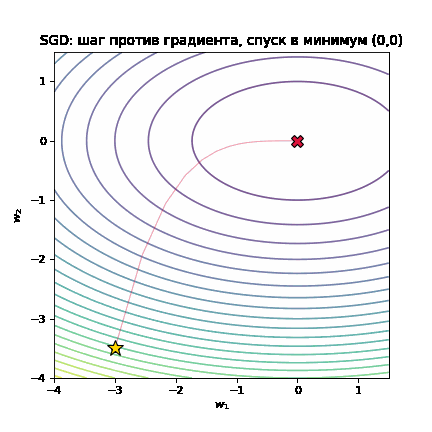

In [4]:
# Настроение SGD: шарик скатывается к минимуму по гладкому оврагу.
kappa = 3.0
f = lambda w: bowl(w, kappa)
g = lambda w: grad_bowl(w, kappa)

path_sgd = run_optimizer('sgd', g, x0=[-3.0, -3.5], steps=40, lr=0.15)
path_anim([path_sgd], f, xlim=(-4, 1.5), ylim=(-4, 1.5),
          title='SGD: шаг против градиента, спуск в минимум (0,0)')

### 1.1.1. Роль learning rate — самый важный гиперпараметр

Один и тот же градиент, три разных $\eta$:

- **маленький $\eta$** — ползём, не успеваем дойти за отведённые шаги;
- **хороший $\eta$** — уверенный спуск;
- **большой $\eta$** — перепрыгиваем минимум и разлетаемся.

Это не метафора: loss **взрывается** при $\eta > 2/\lambda_{\max}$, где $\lambda_{\max}$ — максимальная кривизна. Поэтому `lr` — первое, что настраивают руками.

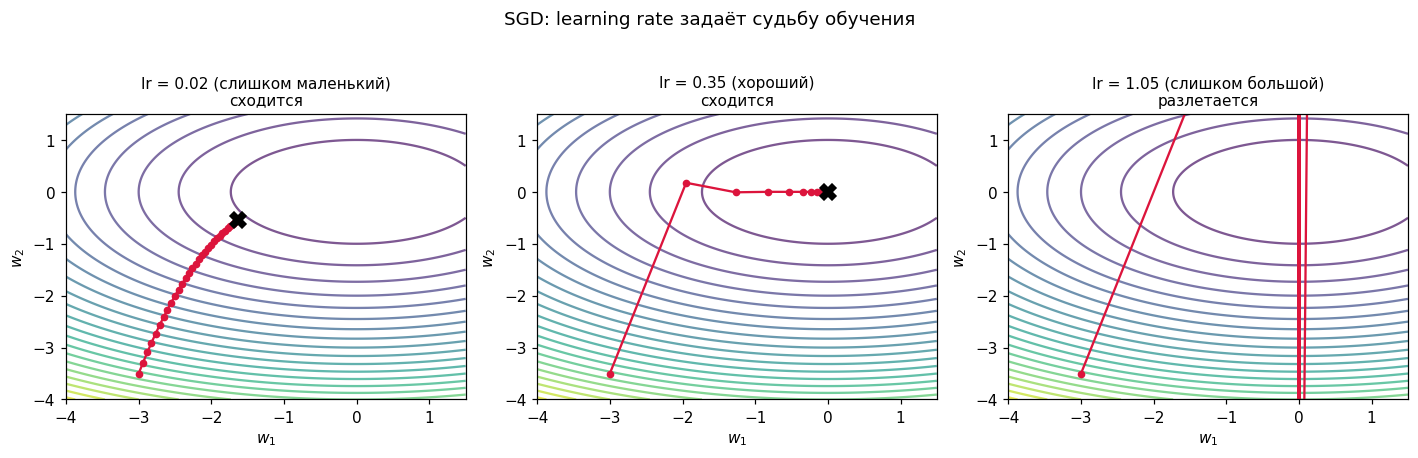

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, lr, tag in zip(axes, [0.02, 0.35, 1.05], ['слишком маленький', 'хороший', 'слишком большой']):
    p = run_optimizer('sgd', g, x0=[-3.0, -3.5], steps=30, lr=lr)
    draw_contours(ax, f, (-4, 1.5), (-4, 1.5))
    ax.plot(p[:, 0], p[:, 1], '-o', color='crimson', ms=4, lw=1.5)
    ax.plot(*p[-1], 'X', color='k', ms=10)
    lost = np.isfinite(p).all() and np.abs(p).max() < 50
    ax.set_title(f'lr = {lr} ({tag})\n' + ('сходится' if lost else 'разлетается'), fontsize=10)
plt.suptitle('SGD: learning rate задаёт судьбу обучения', y=1.03)
plt.tight_layout(); plt.show()

## 1.2. Почему SGD «мечется» в овраге

Вернёмся к оврагу $\kappa=3$ (а в конце лекции — к $\kappa=25$). Градиент вдоль «узкой» оси больше, поэтому SGD делает большие шаги поперёк оврага и маленькие — вдоль. Получается характерный **зигзаг**: мы идём к минимуму, но раскачиваемся из стороны в сторону.

Это первый серьёзный недостаток SGD, который лечат **momentum**.

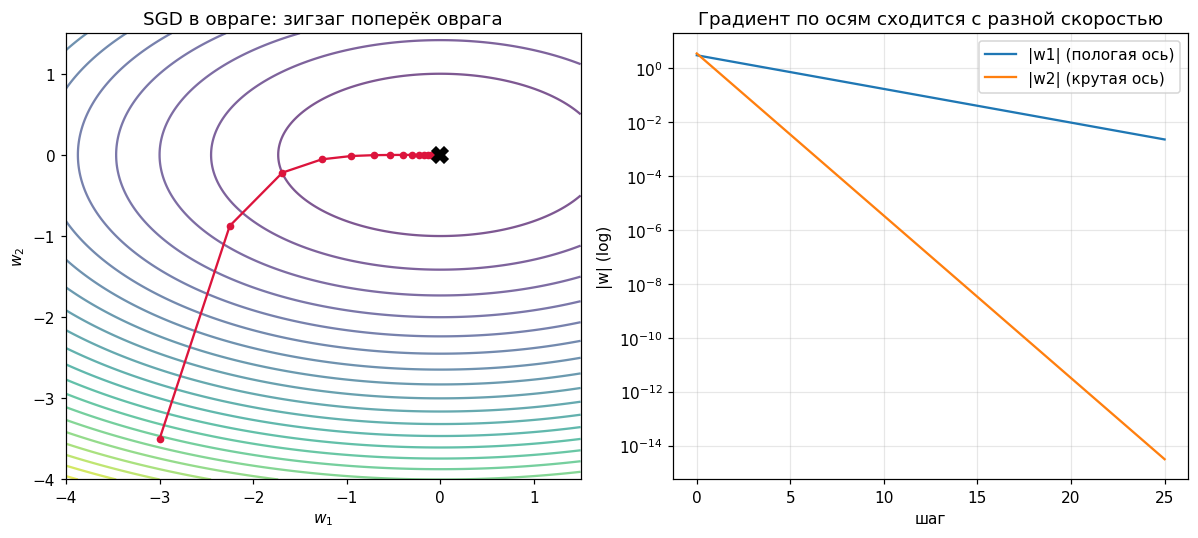

In [6]:
p = run_optimizer('sgd', g, x0=[-3.0, -3.5], steps=25, lr=0.25)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
draw_contours(axes[0], f, (-4, 1.5), (-4, 1.5))
axes[0].plot(p[:, 0], p[:, 1], '-o', color='crimson', ms=4)
axes[0].plot(*p[-1], 'X', color='k', ms=10)
axes[0].set_title('SGD в овраге: зигзаг поперёк оврага')

# покомпонентная сходимость
axes[1].plot(np.abs(p[:, 0]), label='|w1| (пологая ось)')
axes[1].plot(np.abs(p[:, 1]), label='|w2| (крутая ось)')
axes[1].set_yscale('log'); axes[1].set_xlabel('шаг'); axes[1].set_ylabel('|w| (log)')
axes[1].set_title('Градиент по осям сходится с разной скоростью'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 1.3. Full-batch, SGD и мини-батч рядом

Поставим три траектории на один ландшафт, но добавим **шум градиента** — как будто считаем его по разным батчам:

$$g_{\text{batch}} = \nabla J(\theta) + \xi,\qquad \xi \sim \mathcal{N}\Bigl(0,\ \tfrac{\sigma^2}{B}\Bigr)$$

Здесь $B$ — размер батча. Чем больше $B$, тем меньше шум. Следите за тем, как мини-батч «дрожит» вокруг траектории полного градиента.

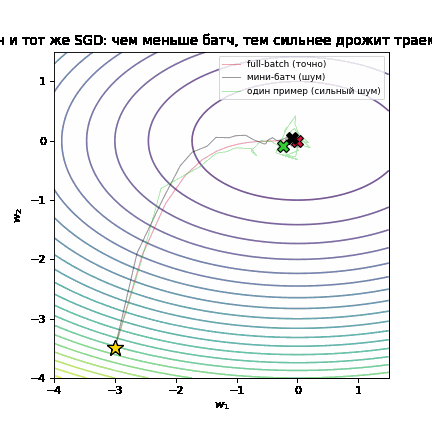

In [7]:
def noisy_grad_fn(kappa, sigma):
    base = lambda w: grad_bowl(w, kappa)
    def g(w):
        return base(w) + np.random.randn(*w.shape) * sigma
    return g

rng = np.random.default_rng(0)
np.random.seed(1)
g_full = lambda w: grad_bowl(w, kappa)
g_batch = noisy_grad_fn(kappa, sigma=0.35)      # мини-батч
g_single = noisy_grad_fn(kappa, sigma=1.1)      # один пример

p_full = run_optimizer('sgd', g_full, [-3.0, -3.5], 36, lr=0.15)
p_batch = run_optimizer('sgd', g_batch, [-3.0, -3.5], 36, lr=0.15)
p_single = run_optimizer('sgd', g_single, [-3.0, -3.5], 36, lr=0.15)

path_anim([p_full, p_batch, p_single], f, (-4, 1.5), (-4, 1.5),
          labels=['full-batch (точно)', 'мини-батч (шум)', 'один пример (сильный шум)'],
          title='Один и тот же SGD: чем меньше батч, тем сильнее дрожит траектория')

**Вывод.** Шум не мешает двигаться в правильном направлении — траектория мини-батча колеблется *вокруг* точной. Именно поэтому стохастический спуск работает. Но у шума есть цена: около минимума мы не «успокоимся», а будем вечно крутиться в облачке размера $\sim\eta\sigma$. Это лечат **затуханием learning rate** и адаптивными методами.

---
# Часть 2. Momentum: инерция движения

## 2.1. Идея

Классический SGD мгновенно «забывает» предыдущее движение: каждый шаг смотрит только на текущий градиент. Поэтому в овраге он бесконечно зигзагует.

**Momentum** добавляет память: накапливаем градиенты в *скорость* $v_t$ и движемся по ней.

$$\boxed{\ v_t = \beta\, v_{t-1} + g_t,\qquad \theta_{t+1} = \theta_t - \eta\, v_t\ }$$

- $\beta \in [0,1)$ — сколько памяти оставляем (обычно $0.9$);
- маленькие и «шумные» компоненты градиента взаимно гасятся;
- **устойчивое** направление — накапливается и разгоняет нас.

**Аналогия.** *Momentum сохраняет за собой направление движения, как будто мы катимся по извилистой дороге.* Шар на спуске не может мгновенно развернуться: он несёт своё движение инерцией, сглаживает мелкие зигзаги и «прокатывается» через небольшие подъёмы.

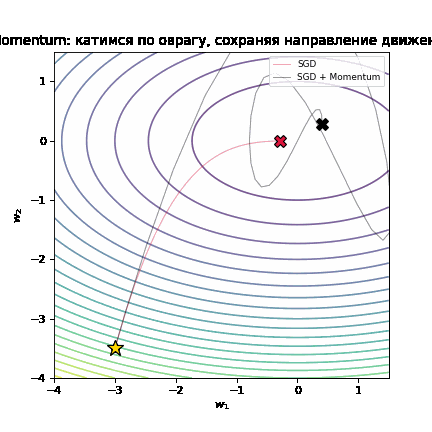

In [8]:
# Сравним чистый SGD и momentum на одном овраге.
p_sgd = run_optimizer('sgd', g, [-3.0, -3.5], 38, lr=0.06)
p_mom = run_optimizer('momentum', g, [-3.0, -3.5], 38, lr=0.06, beta=0.9)

path_anim([p_sgd, p_mom], f, (-4, 1.5), (-4, 1.5),
          labels=['SGD', 'SGD + Momentum'],
          title='Momentum: катимся по оврагу, сохраняя направление движения')

## 2.2. Почему momentum ускоряет: «закон тяжёлого шара»

Распишем, куда идёт $v_t$, если градиент постоянен ($g$):

$$v_t = g(1 + \beta + \beta^2 + \dots) = \frac{g}{1-\beta}
\qquad\Longrightarrow\qquad
\Delta\theta \approx \frac{\eta}{1-\beta}\, g$$

При $\beta=0.9$ эффективный шаг **в 10 раз** больше обычного SGD. То есть momentum — это ещё и автоматическое увеличение learning rate в устойчивом направлении. Ровно поэтому с momentum `lr` берут меньше, чем для чистого SGD.

**Сходимость.** Классический «тяжёлый шар» сходится от $(1-\sqrt{\beta})$-й скорости против $(1-\kappa^{-1})$ у SGD. На плохо обусловленном ландшафте выигрыш огромен.

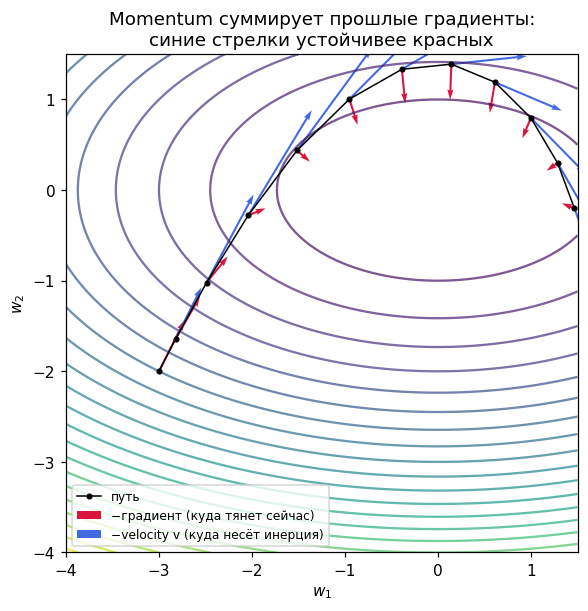

In [9]:
# Наглядно: направление градиента vs направление momentum.
# Возьмём точку в овраге и покажем, куда ведут -g и -v (накопленная скорость).
g_fun = lambda w: grad_bowl(w, 3.0)
x = np.array([-3.0, -2.0])
v = np.zeros(2)
pts, gs, vs = [], [], []
for _ in range(12):
    g_cur = g_fun(x)
    pts.append(x.copy()); gs.append(-g_cur.copy()); vs.append(-v.copy())
    v = 0.9 * v + g_cur
    x = x - 0.06 * v
pts, gs, vs = np.array(pts), np.array(gs), np.array(vs)

fig, ax = plt.subplots(figsize=(6, 6))
draw_contours(ax, f, (-4, 1.5), (-4, 1.5))
ax.plot(pts[:, 0], pts[:, 1], 'o-', color='k', ms=3, lw=1, label='путь')
ax.quiver(pts[:, 0], pts[:, 1], gs[:, 0], gs[:, 1], color='crimson', scale=60,
          width=0.004, label='−градиент (куда тянет сейчас)')
ax.quiver(pts[:, 0], pts[:, 1], vs[:, 0], vs[:, 1], color='royalblue', scale=60,
          width=0.004, label='−velocity v (куда несёт инерция)')
ax.legend(fontsize=8); ax.set_title('Momentum суммирует прошлые градиенты:\nсиние стрелки устойчивее красных')
plt.show()

## 2.3. Nesterov (NAG): «загляни вперёд, потом тормози»

Обычный momentum сначала считает градиент **в текущей точке**, потом делает шаг. Нестеров предлагает смотреть **на шаг вперёд по инерции** и корректировать движение с учётом того, что там окажется.

$$v_t = \beta\, v_{t-1} + g_t,\qquad \boxed{\ \theta_{t+1} = \theta_t - \eta\,\bigl(g_t + \beta\, v_t\bigr)\ }$$

Обратите внимание: в скобках стоит $g_t + \beta v_t$ — это и есть «взгляд вперёд» (ровно так это реализовано в `torch.optim.SGD(nesterov=True)`, и мы сверимся с ним численно в части 6). Другая, эквивалентная по духу запись — считать градиент в «примерочной» точке:

$$v_t = \beta\, v_{t-1} + \nabla J\bigl(\theta_t - \eta\beta\, v_{t-1}\bigr)$$

**Аналогия.** Momentum — это «катимся как есть». Nesterov — это *опытный лыжник*: он смотрит не под ноги, а **на шаг вперёд**, и заранее начинает тормозить перед поворотом. Математически Nesterov имеет лучшую теоретическую скорость сходимости на выпуклых функциях, а на практике почти всегда чуть точнее momentum.

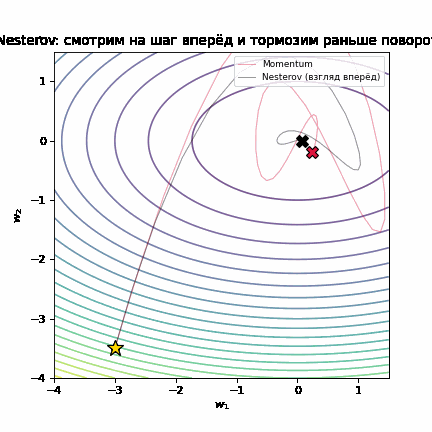

In [10]:
# Иллюстрация «взгляда вперёд»: Nesterov тормозит раньше около минимума.
p_mom = run_optimizer('momentum', g, [-3.0, -3.5], 45, lr=0.05, beta=0.9)
p_nag = run_optimizer('nesterov', g, [-3.0, -3.5], 45, lr=0.05, beta=0.9)

path_anim([p_mom, p_nag], f, (-4, 1.5), (-4, 1.5),
          labels=['Momentum', 'Nesterov (взгляд вперёд)'],
          title='Nesterov: смотрим на шаг вперёд и тормозим раньше поворота')

## 2.4. Осторожно с momentum: он умеет «проскакивать»

У инерции есть обратная сторона — **overshoot**. Если `lr` слишком большой, шар разгоняется и вылетает из минимума, потом возвращается и снова пролетает. На выпуклой задаче это само затухнет, но на нейросети может дать нестабильность. Отсюда правило: **с momentum `lr` уменьшают** (часто в 2–5 раз по сравнению с чистым SGD).

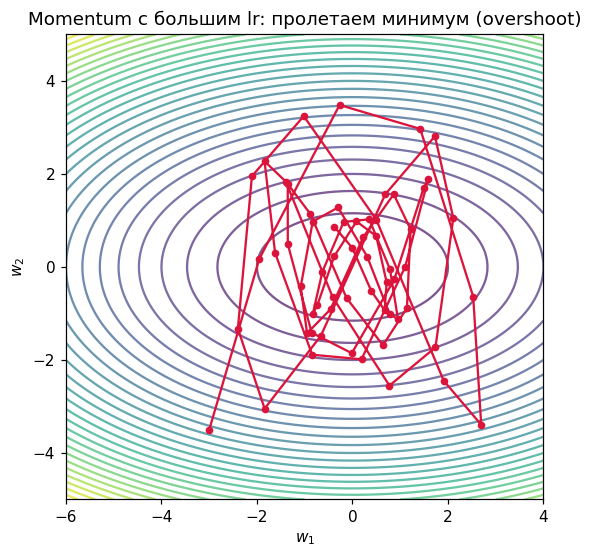

|w| на последнем шаге: [0.39 0.87]


In [11]:
# Overshoot: too large lr with momentum.
p_big = run_optimizer('momentum', g, [-3.0, -3.5], 60, lr=0.35, beta=0.95)
fig, ax = plt.subplots(figsize=(5.6, 5.6))
draw_contours(ax, f, (-6, 4), (-5, 5))
ax.plot(p_big[:, 0], p_big[:, 1], '-o', color='crimson', ms=4)
ax.set_title('Momentum с большим lr: пролетаем минимум (overshoot)')
plt.show()
print('|w| на последнем шаге:', np.round(np.abs(p_big[-1]), 2))

---
# Часть 3. Адаптивные методы: свой learning rate каждому параметру

## 3.1. Зачем

У SGD один `lr` на все параметры. Но представьте признаки разного масштаба: одному весу нужен большой шаг, другому — крошечный. Идея адаптивных методов: **масштабировать шаг каждого параметра по его собственной истории градиентов**.

$$\theta_{t+1} = \theta_t - \eta\,\frac{g_t}{\sqrt{s_t} + \varepsilon}$$

где $s_t$ — «память» о том, насколько большими были градиенты этого параметра раньше.

- большие градиенты → большой $\sqrt{s_t}$ → **шаг уменьшается** (параметр и так активен);
- маленькие градиенты → маленький $\sqrt{s_t}$ → **шаг увеличивается** (параметр «спит», его надо растолкать).

**Аналогия.** *У каждого бегуна свой запас сил*: тот, кто уже много пробежал (большие градиенты), замедляется, а свежий — бежит бодро. Итог: все параметры приходят «примерно к нулю» одновременно.

## 3.2. Adagrad: копим **всю** историю

$$\boxed{\ s_t = s_{t-1} + g_t^2,\qquad \theta_{t+1} = \theta_t - \eta\,\frac{g_t}{\sqrt{s_t}+\varepsilon}\ }$$

$s_t$ только растёт, значит эффективный learning rate монотонно **падает**. Плюсы: отлично работает на разреженных признаках (NLP, embeddings). Минус: к концу обучения шаг становится настолько маленьким, что модель «замирает» задолго до оптимума.

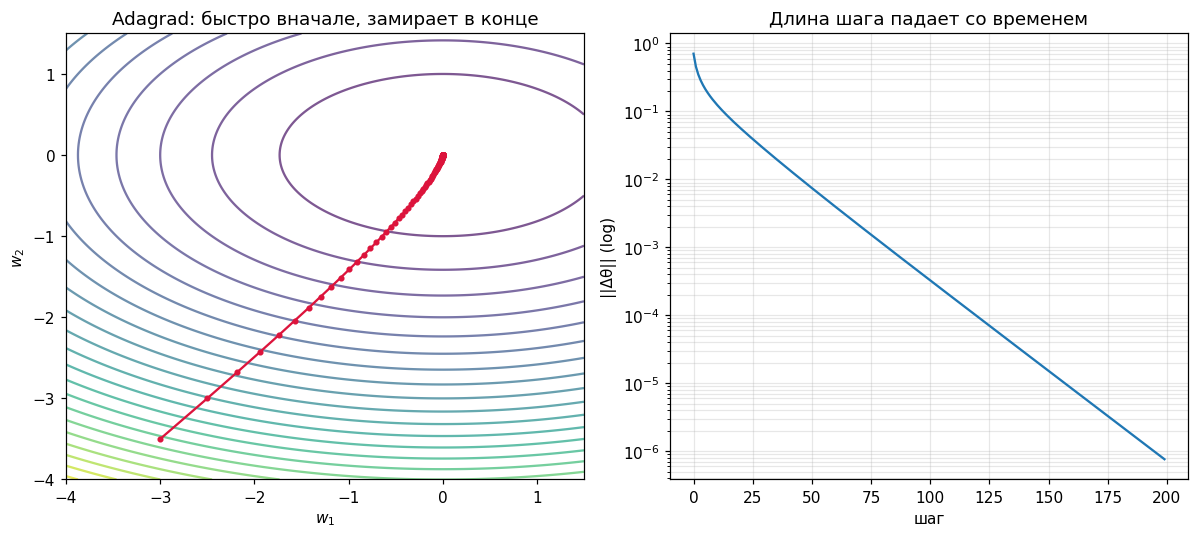

In [12]:
# Adagrad на овраге: к концу шаг почти исчезает.
p_ada = run_optimizer('adagrad', g, [-3.0, -3.5], 200, lr=0.5)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
draw_contours(axes[0], f, (-4, 1.5), (-4, 1.5))
axes[0].plot(p_ada[:, 0], p_ada[:, 1], '-o', color='crimson', ms=3)
axes[0].set_title('Adagrad: быстро вначале, замирает в конце')

step = np.linalg.norm(np.diff(p_ada, axis=0), axis=1)
axes[1].plot(step)
axes[1].set_yscale('log'); axes[1].set_xlabel('шаг'); axes[1].set_ylabel('||Δθ|| (log)')
axes[1].set_title('Длина шага падает со временем'); axes[1].grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()

## 3.3. RMSprop: забываем старое

Проблема Adagrad — *бесконечная память*. RMSprop (Хинтон, 2012) заменяет сумму на **экспоненциальное скользящее среднее**:

$$\boxed{\ s_t = \beta\, s_{t-1} + (1-\beta)\, g_t^2,\qquad \theta_{t+1} = \theta_t - \eta\,\frac{g_t}{\sqrt{s_t}+\varepsilon}\ }$$

Теперь «память» ограничена: старые градиенты постепенно забываются, и шаг **не затухает до нуля**.

**Аналогия.** *Помним только недавнюю историю, чтобы не застрять навсегда.* $\beta\approx0.9$ — золотая середина между шумом и инерцией оценки.

**Adadelta** (2012) — близкий родственник: убирает из RMSprop ещё и learning rate, нормируя шаг на скользящее среднее **самих обновлений**. Полезно, когда $\eta$ подбирать лень.

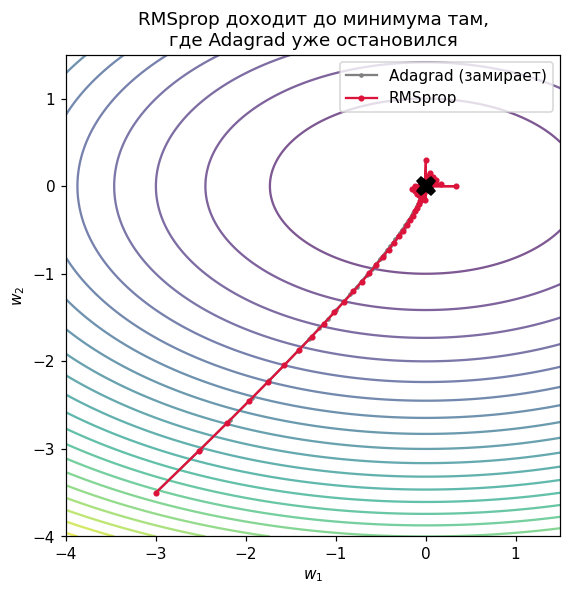

In [13]:
p_rms = run_optimizer('rmsprop', g, [-3.0, -3.5], 200, lr=0.15, beta=0.9)
fig, ax = plt.subplots(figsize=(5.8, 5.8))
draw_contours(ax, f, (-4, 1.5), (-4, 1.5))
ax.plot(p_ada[:, 0], p_ada[:, 1], '-o', color='gray', ms=2, label='Adagrad (замирает)')
ax.plot(p_rms[:, 0], p_rms[:, 1], '-o', color='crimson', ms=3, label='RMSprop')
ax.plot(0, 0, 'X', color='k', ms=12)
ax.legend(); ax.set_title('RMSprop доходит до минимума там,\nгде Adagrad уже остановился')
plt.show()

## 3.4. Adam: momentum + адаптивность = «золотой стандарт»

Adam (Kingma & Ba, 2014) соединяет обе идеи:

- **первый момент** $m_t$ (как momentum) — сглаживает направление;
- **второй момент** $v_t$ (как RMSprop) — даёт каждому параметру свой масштаб.

$$\boxed{\;
\begin{aligned}
m_t &= \beta_1 m_{t-1} + (1-\beta_1)\, g_t, & \hat m_t &= \frac{m_t}{1-\beta_1^{\,t}},\\[2pt]
v_t &= \beta_2 v_{t-1} + (1-\beta_2)\, g_t^2, & \hat v_t &= \frac{v_t}{1-\beta_2^{\,t}},\\[2pt]
\theta_{t+1} &= \theta_t - \eta\,\dfrac{\hat m_t}{\sqrt{\hat v_t}+\varepsilon}
\end{aligned}
\;}$$

**Ключевая деталь — поправка на смещение (bias correction).** В начале $m_0=v_0=0$, поэтому «сырые» оценки занижены. Деление на $1-\beta_1^t$ и $1-\beta_2^t$ в первые шаги почти отменяет это занижение и даёт **корректный разгон** на старте.

**Аналогия.** *У каждого веса свой водитель с круиз-контролем и персональным тормозом:* он запоминает, куда ехал (momentum), чутко реагирует на собственные «колдобины» (адаптивность) и специально стартует с уверенного разгона.

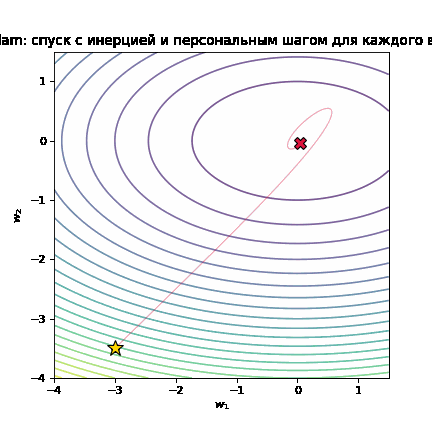

In [14]:
p_adam = run_optimizer('adam', g, [-3.0, -3.5], 70, lr=0.2)
path_anim([p_adam], f, (-4, 1.5), (-4, 1.5),
          title='Adam: спуск с инерцией и персональным шагом для каждого веса')

### 3.4.1. Зачем нужны $\beta_1$ и $\beta_2$

- $\beta_1=0.9$ — «насколько долго помним направление» (~10 шагов);
- $\beta_2=0.999$ — «насколько долго помним масштаб градиента» (~1000 шагов). Стандарт из статьи настолько хорош, что его почти никогда не меняют;
- $\varepsilon$ — чисто техническая защита от деления на ноль при $v_t\to0$; влиять на обучение она почти не должна, но при слишком большой $\varepsilon$ (например, `1e-4`) шаг «деградирует» к обычному SGD. В PyTorch по умолчанию `eps=1e-8`.

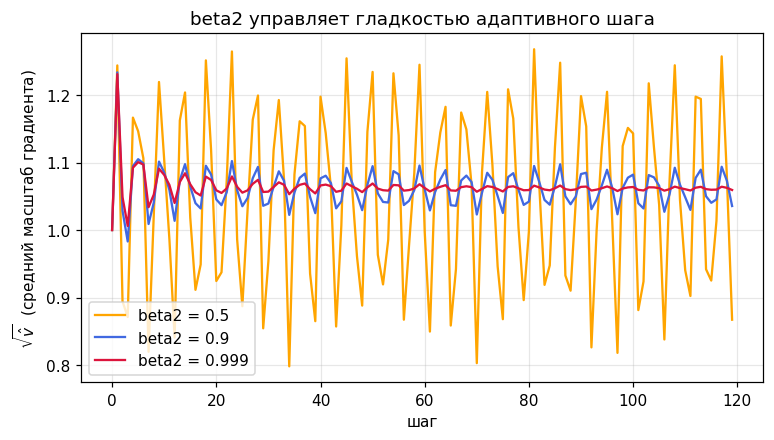

In [15]:
# Влияние beta2: маленькая beta2 -> шумная норма; большая -> плавная, но инертная.
fig, ax = plt.subplots(figsize=(8, 4.2))
g_track = np.array([np.array([np.cos(0.7*t)*2.0, np.sin(1.3*t)]) for t in range(120)])
for b2, c in [(0.5, 'orange'), (0.9, 'royalblue'), (0.999, 'crimson')]:
    s = np.zeros(2)
    norm = []
    for t, gt in enumerate(g_track):
        s = b2 * s + (1 - b2) * gt ** 2
        s_hat = s / (1 - b2 ** (t + 1))
        norm.append(np.sqrt(s_hat).mean())
    ax.plot(norm, color=c, label=f'beta2 = {b2}')
ax.set_xlabel('шаг'); ax.set_ylabel(r'$\sqrt{\hat v}$  (средний масштаб градиента)')
ax.set_title('beta2 управляет гладкостью адаптивного шага'); ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 3.5. AdamW: где именно прикручен weight decay

Тонкое, но важное место. В L2-регуляризации мы добавляли $\lambda\theta$ **внутрь градиента**:

$$g_t \leftarrow g_t + \lambda\theta_t$$

Adam нормирует этот суммарный градиент на $\sqrt{v_t}$ — то есть **штраф за веса тоже делится на адаптивный масштаб**. У весов с маленьким градиентом (а потому большим эффективным шагом) регуляризация начинает работать *сильнее*, чем задумано. Это неправильно.

**AdamW** (Loshchilov & Hutter, 2017) вычитает weight decay **напрямую из параметра**, уже после адаптивного шага:

$$\boxed{\ \theta_{t+1} = \theta_t - \eta\left(\frac{\hat m_t}{\sqrt{\hat v_t}+\varepsilon} + \lambda\,\theta_t\right)\ }$$

**Аналогия.** *То же, что Adam, но штраф за вес списывают отдельной строкой, а не прячут в градиент* — от этого регуляризация работает так, как задумано, и модели обобщают лучше.

Сегодня **AdamW — стандарт по умолчанию**, особенно для трансформеров. В `torch.optim.AdamW` у `weight_decay` уже правильная семантика.

In [16]:
# Продемонстрируем разницу L2-в-Adam и AdamW на «плоских» весах:
# у параметра с крошечным градиентом обычный Adam «случайно» тормозит его декэем сильнее.
# Здесь просто сравним масштаб эффективного decay.
theta = 1.0
lam, lr = 0.1, 0.01
# Adam + L2-внутри (Adam-L2): decay проходит через деление на sqrt(v)
v_small = 1e-6
eff_adamL2 = lr * lam * theta / (np.sqrt(v_small) + 1e-8)
# AdamW: decay применяется к параметру напрямую
eff_adamw = lr * lam * theta
print('эффект decay на «спящий» вес при sqrt(v)=1e-3:')
print('  Adam  + L2 в градиенте :', round(eff_adamL2, 4), '(взрывоопасно большой)')
print('  AdamW (decoupled)      :', round(eff_adamw, 4), '(ровно как задумано)')

эффект decay на «спящий» вес при sqrt(v)=1e-3:
  Adam  + L2 в градиенте : 1.0 (взрывоопасно большой)
  AdamW (decoupled)      : 0.001 (ровно как задумано)


## 3.6. Почему Adam хорош, но не волшебный

**Плюсы:** быстрая сходимость «из коробки», терпимость к плохому масштабу признаков, почти не требует подбора `lr` (стандарт `1e-3`), удобен на разреженных градиентах.

**Известные минусы:**

- **Не всегда лучший test-результат.** На многих CV-задачах хорошо настроенный SGD + momentum обобщает лучше Adam. Adam быстро сходится к «резкому» минимуму; SGD с шумом — к более «плоскому» и потому более переносимому. Отсюда приём: **учите Adam'ом, а «дотюнивайте» SGD**.
- **Weight decay нужно делать правильно** — отсюда AdamW.
- **Adam может расходиться** при некоторых задачах; тогда лечит уменьшение `lr` или $\beta_2$ (например, $0.99$).

**Аналогия.** *Adam — как автоматическая коробка передач: едет почти всегда, но настоящий гонщик иногда переключается на механику (SGD) ради последних секунд.*

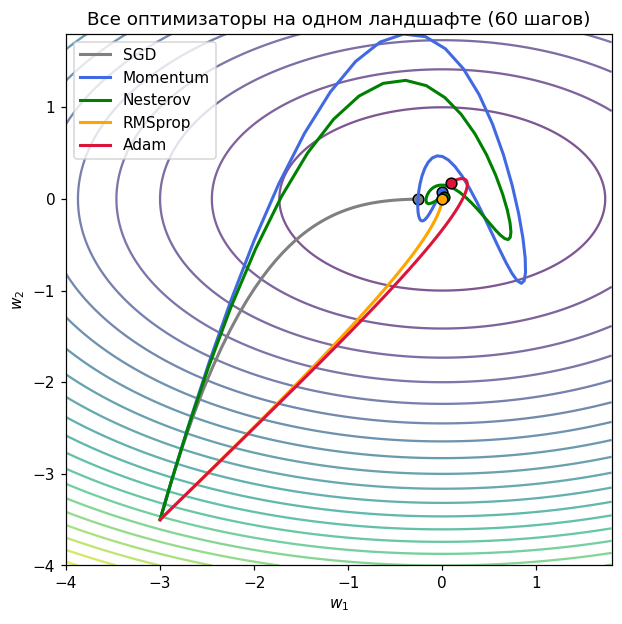

In [17]:
# Один и тот же овраг: как разные оптимизаторы проходят путь за 60 шагов.
paths = {
    'SGD': run_optimizer('sgd', g, [-3.0, -3.5], 60, lr=0.04),
    'Momentum': run_optimizer('momentum', g, [-3.0, -3.5], 60, lr=0.02, beta=0.9),
    'Nesterov': run_optimizer('nesterov', g, [-3.0, -3.5], 60, lr=0.022, beta=0.9),
    'RMSprop': run_optimizer('rmsprop', g, [-3.0, -3.5], 60, lr=0.1, beta=0.9),
    'Adam': run_optimizer('adam', g, [-3.0, -3.5], 60, lr=0.12),
}
fig, ax = plt.subplots(figsize=(6.4, 6.4))
draw_contours(ax, f, (-4, 1.8), (-4, 1.8))
for (name, p), c in zip(paths.items(), ['gray', 'royalblue', 'green', 'orange', 'crimson']):
    ax.plot(p[:, 0], p[:, 1], '-', color=c, lw=2, label=name)
    ax.plot(*p[-1], 'o', color=c, ms=7, markeredgecolor='k')
ax.legend(); ax.set_title('Все оптимизаторы на одном ландшафте (60 шагов)')
plt.show()

## 3.7. Адаптивность сглаживает ландшафт

Ключевое наблюдение: **Adam фактически превращает вытянутый овраг в почти круглый**. Взгляните — в метрике, которую Adam «видит», изолинии становятся кругами, и по ним можно идти быстрым прямым шагом. Это и есть смысл нормировки на $\sqrt{v_t}$.

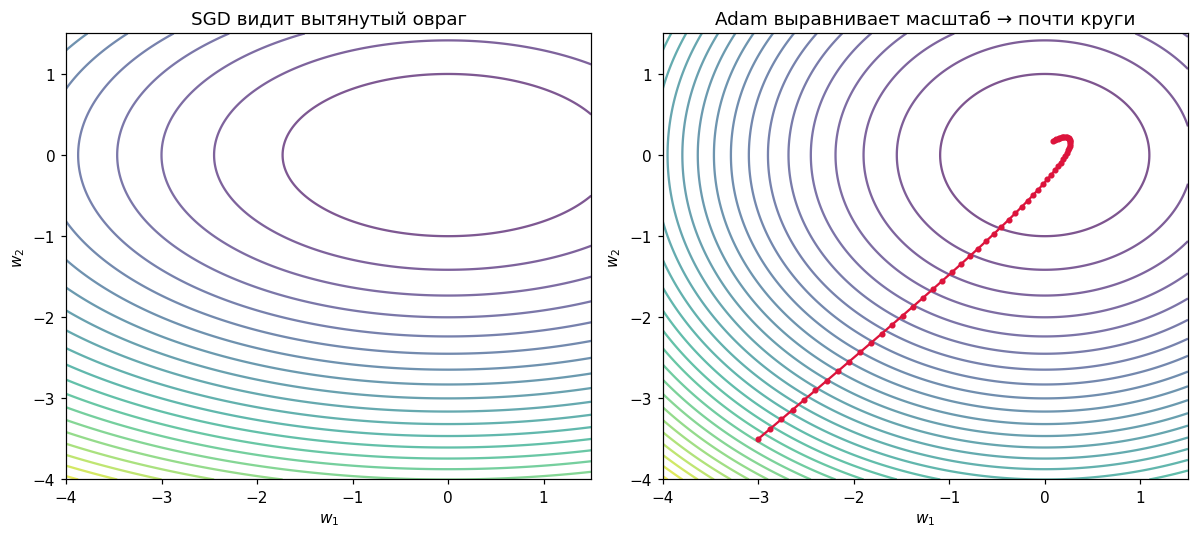

In [18]:
# «Круглый» ландшафт, который видит Adam: нормируем оси его адаптивным масштабом.
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
draw_contours(axes[0], f, (-4, 1.5), (-4, 1.5))
axes[0].set_title('SGD видит вытянутый овраг')

# Adam адаптивно масштабирует: строим ландшафт в координатах, где масштаб сглажен.
def f_round(w):  # условно «то, что видит Adam»: почти сферическая функция
    return 0.5 * (w[..., 0] ** 2 + 1.2 * w[..., 1] ** 2)
draw_contours(axes[1], f_round, (-4, 1.5), (-4, 1.5))
p = paths['Adam']
axes[1].plot(p[:, 0], p[:, 1], '-o', color='crimson', ms=3)
axes[1].set_title('Adam выравнивает масштаб → почти круги')
plt.tight_layout(); plt.show()

---
# Часть 4. Узкий овраг: где momentum и Adam вырываются вперёд

Возьмём «злой» ландшафт — число обусловленности $\kappa=25$. Теперь вдоль одной оси кривизна в 25 раз больше: чистый SGD будет долго метаться поперёк, почти не продвигаясь вдоль.

Это не учебный каприз: так выглядят **реальные** ландшафты нейросетей — почти всюду почти плоские, а в отдельных направлениях очень крутые.

## 4.1. SGD застревает в овраге

Смотрите на зигзаг: SGD честно идёт вниз, но поперёк оврага уходит дальше, чем вдоль. За те же шаги momentum и Adam успевают дойти до минимума.

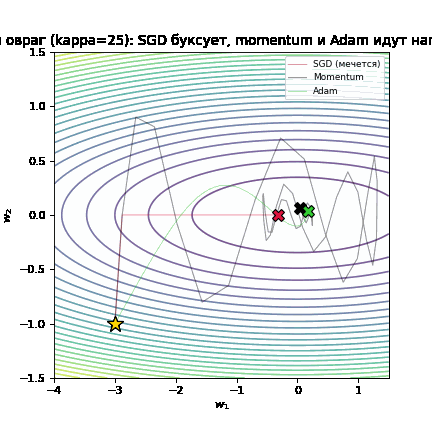

In [19]:
kappa_hard = 25.0
f_hard = lambda w: bowl(w, kappa_hard)
g_hard = lambda w: grad_bowl(w, kappa_hard)

p_sgd = run_optimizer('sgd', g_hard, [-3.0, -1.0], 55, lr=0.04)
p_mom = run_optimizer('momentum', g_hard, [-3.0, -1.0], 55, lr=0.04, beta=0.9)
p_adam = run_optimizer('adam', g_hard, [-3.0, -1.0], 55, lr=0.1)

path_anim([p_sgd, p_mom, p_adam], f_hard, (-4, 1.5), (-1.5, 1.5),
          labels=['SGD (мечется)', 'Momentum', 'Adam'],
          title='Узкий овраг (kappa=25): SGD буксует, momentum и Adam идут напрямую')

## 4.2. Почему momentum спасает именно здесь

Вдоль оврага градиент маленький и **постоянный** → компонента скорости накапливается линейно, и мы разгоняемся. Поперёк оврага градиент большой, но **знакопеременный** → соседние вклады взаимно гасятся в сумме $v_t$.

$$\underbrace{\sum \beta^k g_{t-k}}_{\text{вдоль: складывается}} \quad\text{против}\quad \underbrace{\sum \beta^k (\pm g)}_{\text{поперёк: вычитается}}$$

Так «усреднение истории» само убивает зигзаг. Именно поэтому momentum так любят в CV-задачах.

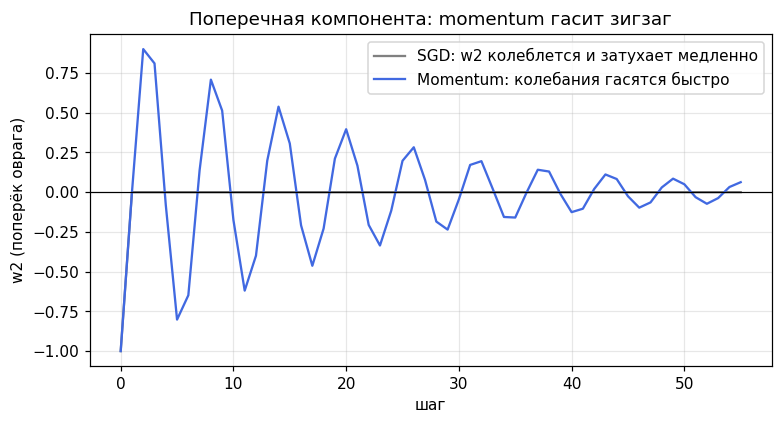

In [20]:
# Покажем затухание зигзага: амплитуда поперечных колебаний у SGD и momentum.
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(p_sgd[:, 1], label='SGD: w2 колеблется и затухает медленно', color='gray')
ax.plot(p_mom[:, 1], label='Momentum: колебания гасятся быстро', color='royalblue')
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('шаг'); ax.set_ylabel('w2 (поперёк оврага)')
ax.set_title('Поперечная компонента: momentum гасит зигзаг'); ax.legend(); ax.grid(alpha=0.3)
plt.show()

---
# Часть 5. Современные оптимизаторы: кто есть кто

AdamW — дефолт, но вокруг него выросло целое семейство. Разберём самых используемых и когда они нужны.

## 5.1. Nadam: Adam + Нестеров

**Идея.** Заменить в Adam «взгляд назад» (обычный momentum) на «взгляд вперёд» от Нестерова.

$$\theta_{t+1} = \theta_t - \eta\,\frac{\beta_1 \hat m_t + (1-\beta_1)\dfrac{g_t}{1-\beta_1^t}}{\sqrt{\hat v_t}+\varepsilon}$$

**Когда нужен.** Почти всегда работает на уровне Adam или чуть лучше; полезен, если важна скорость в начале. В PyTorch — `torch.optim.NAdam`.

**Аналогия.** *Водитель Adam, который смотрит на два поворота вперёд.*

## 5.2. RAdam: Adam с тёплым стартом

**Проблема.** В первые шаги оценка $\hat v_t$ основана на 1–2 градиентах — она шумная, и Adam может уйти «не туда». Bias correction помогает, но не спасает от высокой дисперсии.

**Идея.** RAdam (Rectified Adam, 2019) вводит **динамический warmup**: пока статистика второго момента ненадёжна, шаг уменьшается (по сути, «нагревается»), и только после накопления достаточной истории включается полноценный Adam.

**Когда нужен.** Когда нельзя позволить себе ручной learning rate warmup, а обучение нестабильно на старте. В PyTorch — `torch.optim.RAdam`.

**Аналогия.** *Не даём газа, пока не прогрели двигатель.*

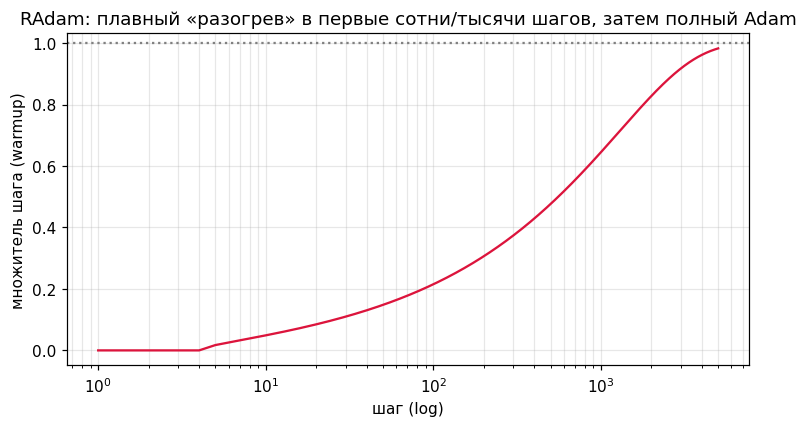

In [21]:
# Warmup RAdam: первые шаги с искусственно маленьким шагом, потом полный Adam.
# Смоделируем коэффициент warmup: rho_t растёт с числом шагов.
b2 = 0.999
t = np.arange(1, 5000)
rho = 2 / (1 - b2) - 1
rho_t = rho - 2 * t * b2 ** t / (1 - b2 ** t)
inner = (rho_t - 4) * (rho_t - 2) * rho / ((rho - 4) * (rho - 2) * rho_t)
rect = np.where(rho_t > 4, np.sqrt(np.maximum(inner, 0.0)), 0.0)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t, rect, color='crimson')
ax.axhline(1, color='gray', ls=':')
ax.set_xscale('log')
ax.set_xlabel('шаг (log)'); ax.set_ylabel('множитель шага (warmup)')
ax.set_title('RAdam: плавный «разогрев» в первые сотни/тысячи шагов, затем полный Adam')
ax.grid(alpha=0.3, which='both'); plt.show()

## 5.3. LAMB и LARS: для огромных батчей

**LARS** (2017) и **LAMB** (2019) масштабируют адаптивный шаг к **норме весов слоя**:

$$\theta_{t+1} = \theta_t - \eta\,\frac{\|\theta_t\|}{\|\nabla\text{-часть}\|}\cdot(\text{шаг Adam})$$

Это позволяет обучать на **гигантских батчах** (тысячи-десятки тысяч): каждый слой получает шаг, согласованный с его масштабом, и «громкие» слои не подавляют «тихие».

**Когда нужны.** Распределённое обучение BERT/GPT, батчи в десятки тысяч. В обычной жизни не нужны.

**Аналогия.** *Раздаём всем слоям одинаковый бюджет шага, а не «кто громче кричит».*

## 5.4. Adafactor: Adam без хранения полной матрицы моментов

**Проблема.** Adam хранит **два** буфера размером с модель (`m` и `v`) — это ×3 памяти на параметры. Для больших трансформеров больно.

**Идея.** Adafactor (2018) хранит второй момент не матрицей, а в виде **факторизации на строки и столбцы** (rank-1 аппроксимация). Память падает почти в разы, точность почти не теряется. Используется при обучении T5 и больших языковых моделей.

**Аналогия.** *Вместо полной таблицы помним только сумму по строкам и столбцам — почти то же, но дешевле.*

## 5.5. Lion и Sophia: свежие идеи

- **Lion** (2023): шаг берётся от **знака** момента обновления, обновление $= -\eta\,\text{sign}(\ldots)$. Проще и дешевле Adam (одно состояние вместо двух), часто немного быстрее. Знак отбрасывает величину — остаётся только направление.
- **Sophia** (2023): использует **оценку кривизны** (второй порядок), клипуя шаг. Быстрее Adam на языковых моделях за счёт меньшего числа шагов.

**Аналогия:** Lion — *идём «в ту сторону», не сверяя силу*; Sophia — *едем быстрее там, где дорога прямая, и тормозим на поворотах*.

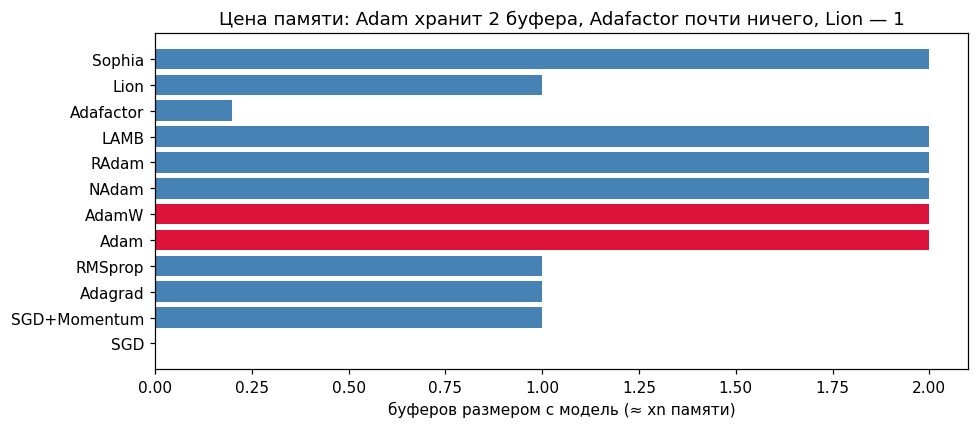

In [22]:
# Сравним по одному признаку: сколько «памяти» под state у каждого оптимизатора.
memory = {
    'SGD': 0, 'SGD+Momentum': 1, 'Adagrad': 1, 'RMSprop': 1,
    'Adam': 2, 'AdamW': 2, 'NAdam': 2, 'RAdam': 2,
    'LAMB': 2, 'Adafactor': 0.2, 'Lion': 1, 'Sophia': 2,
}
fig, ax = plt.subplots(figsize=(9, 4))
names = list(memory); vals = [memory[n] for n in names]
colors = ['crimson' if n in ('Adam', 'AdamW') else 'steelblue' for n in names]
ax.barh(names, vals, color=colors)
ax.set_xlabel('буферов размером с модель (≈ xn памяти)')
ax.set_title('Цена памяти: Adam хранит 2 буфера, Adafactor почти ничего, Lion — 1')
plt.tight_layout(); plt.show()

## 5.6. Шпаргалка: что выбирать

| Ситуация | Разумный выбор |
|---|---|
| «Просто хочу, чтобы обучилось» | **AdamW**, `lr=1e-3`, `weight_decay=0.01` |
| Трансформеры / NLP | **AdamW**, warmup + cosine schedule |
| CNN, важно максимальное качество | **SGD + momentum (nesterov)**, `lr` подобрать |
| Разреженные признаки, эмбеддинги | **Adagrad** или **AdamW** |
| Нет памяти на 2 буфера Adam | **Adafactor**, **Lion** |
| Гигантские батчи, распределённое | **LAMB / LARS** |
| Нестабильность на старте | **RAdam** / ручной warmup |
| Хочется последние проценты скорости | **NAdam**, **Lion**, **Sophia** |

---
# Часть 6. Оптимизаторы в PyTorch

## 6.1. Общий интерфейс `torch.optim`

Все оптимизаторы в PyTorch работают одинаково:

```python
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)

for xb, yb in loader:
    opt.zero_grad()          # 1) обнулить старые градиенты
    loss = loss_fn(model(xb), yb)
    loss.backward()          # 2) посчитать градиенты (backprop)
    opt.step()               # 3) сделать шаг по правилу оптимизатора
```

Ключевое отличие от семинара с `optim.SGD`: у momentum/Adam/... есть **внутреннее состояние** (буферы $v$, $m$, $s_t$). Оно хранится в `optimizer.state` и **сохраняется в чекпоинт** вместе с весами модели:

```python
torch.save({'model': model.state_dict(),
            'optim': optimizer.state_dict()}, 'ckpt.pt')
```

Если забыть сохранить состояние оптимизатора, обучение «дёрнется» при возобновлении: Adam потеряет накопленные моменты.

In [23]:
# Посмотрим на внутреннее состояние разных оптимизаторов.
# Важно создавать их с СВОИМИ моделями, иначе буферы «перетекают» между оптимизаторами.
def make_model(h=64):
    return nn.Sequential(
        nn.Linear(2, h), nn.ReLU(),
        nn.Linear(h, h), nn.ReLU(),
        nn.Linear(h, 2),
    )

x = torch.randn(16, 2); y = torch.randint(0, 2, (16,))
crit = nn.CrossEntropyLoss()

makers = {
    'SGD':            lambda p: torch.optim.SGD(p, lr=0.1),
    'SGD+momentum':   lambda p: torch.optim.SGD(p, lr=0.1, momentum=0.9),
    'SGD+nesterov':   lambda p: torch.optim.SGD(p, lr=0.1, momentum=0.9, nesterov=True),
    'RMSprop':        lambda p: torch.optim.RMSprop(p, lr=1e-3),
    'Adam':           lambda p: torch.optim.Adam(p, lr=1e-3),
    'AdamW':          lambda p: torch.optim.AdamW(p, lr=1e-3, weight_decay=0.01),
    'NAdam':          lambda p: torch.optim.NAdam(p, lr=1e-3),
    'RAdam':          lambda p: torch.optim.RAdam(p, lr=1e-3),
}
for name, mk in makers.items():
    torch.manual_seed(0)
    model = make_model()
    opt = mk(model.parameters())
    opt.zero_grad()
    crit(model(x), y).backward()
    opt.step()
    state = opt.state_dict()['state']
    total_floats = 0
    keys = set()
    for v in state.values():
        for k, val in v.items():
            if torch.is_tensor(val) and val.numel() > 0:
                keys.add(k)
                total_floats += val.numel()
    n_params = len(state)
    if total_floats == 0:
        print(f'{name:>13}: внутреннего состояния нет (память не нужна)')
    else:
        print(f'{name:>13}: параметров = {n_params:>2} | буферы: {sorted(keys)} | тензорных чисел ≈ {total_floats}')

          SGD: внутреннего состояния нет (память не нужна)
 SGD+momentum: параметров =  6 | буферы: ['momentum_buffer'] | тензорных чисел ≈ 4482
 SGD+nesterov: параметров =  6 | буферы: ['momentum_buffer'] | тензорных чисел ≈ 4482
      RMSprop: параметров =  6 | буферы: ['square_avg'] | тензорных чисел ≈ 4482
         Adam: параметров =  6 | буферы: ['exp_avg', 'exp_avg_sq', 'step'] | тензорных чисел ≈ 8970
        AdamW: параметров =  6 | буферы: ['exp_avg', 'exp_avg_sq', 'step'] | тензорных чисел ≈ 8970
        NAdam: параметров =  6 | буферы: ['exp_avg', 'exp_avg_sq', 'mu_product', 'step'] | тензорных чисел ≈ 8976
        RAdam: параметров =  6 | буферы: ['exp_avg', 'exp_avg_sq', 'step'] | тензорных чисел ≈ 8970


## 6.2. Сверяем: `torch.optim` == наши формулы

Обязательная проверка: прогоним `torch.optim.SGD(momentum)` и `torch.optim.Adam` **шаг в шаг** против наших numpy-реализаций на одной и той же функции. Если совпадёт — формулы верны.

In [24]:
def torch_optimizer_path(opt_name, x0, grad_np, steps=50, **kw):
    '''Гоняем torch.optim по той же функции через параметр-тензор и .grad.'''
    p = torch.tensor(x0, dtype=torch.float64, requires_grad=True)
    if opt_name == 'sgd':
        opt = torch.optim.SGD([p], lr=kw.get('lr', 0.1))
    elif opt_name == 'momentum':
        opt = torch.optim.SGD([p], lr=kw.get('lr', 0.1), momentum=kw.get('beta', 0.9))
    elif opt_name == 'nesterov':
        opt = torch.optim.SGD([p], lr=kw.get('lr', 0.1), momentum=kw.get('beta', 0.9), nesterov=True)
    elif opt_name == 'rmsprop':
        opt = torch.optim.RMSprop([p], lr=kw.get('lr', 0.1), alpha=kw.get('beta', 0.9))
    elif opt_name == 'adam':
        opt = torch.optim.Adam([p], lr=kw.get('lr', 0.1), betas=(kw.get('beta1', 0.9), kw.get('beta2', 0.999)))
    path = [p.detach().numpy().copy()]
    for _ in range(steps):
        opt.zero_grad()
        g = grad_np(p.detach().numpy())
        p.grad = torch.tensor(g, dtype=torch.float64)
        opt.step()
        path.append(p.detach().numpy().copy())
    return np.array(path)

x0 = [-3.0, -3.5]
checks = [
    ('sgd', dict(lr=0.1)),
    ('momentum', dict(lr=0.1, beta=0.9)),
    ('nesterov', dict(lr=0.1, beta=0.9)),
    ('rmsprop', dict(lr=0.1, beta=0.9)),
    ('adam', dict(lr=0.1, beta1=0.9, beta2=0.999)),
]
for name, kw in checks:
    pt = torch_optimizer_path(name, x0, g, steps=40, **kw)
    pn = run_optimizer(name, g, x0, steps=40, **kw)
    err = np.abs(pt - pn).max()
    print(f'[{ "OK " if err < 1e-6 else "FAIL"}] {name:>9}: torch vs numpy  max diff = {err:.2e}')

[OK ]       sgd: torch vs numpy  max diff = 4.44e-16
[OK ]  momentum: torch vs numpy  max diff = 8.88e-16
[OK ]  nesterov: torch vs numpy  max diff = 4.44e-16
[OK ]   rmsprop: torch vs numpy  max diff = 1.11e-16
[OK ]      adam: torch vs numpy  max diff = 2.78e-16


---
# Часть 7. Эксперименты на настоящей нейросети

## 7.1. Задача

Возьмём **нелинейную** бинарную задачу с двумя признаками (XOR-подобную) — её нельзя решить линейной моделью, нужен хотя бы один скрытый слой. На ней разница между оптимизаторами проявляется ярко.

Сразу соблюдаем правила курса: фиксируем seed, выбираем устройство device-agnostic, используем `DataLoader` с `num_workers` и `pin_memory`.

X: (1024, 2) | классы: [511, 513]


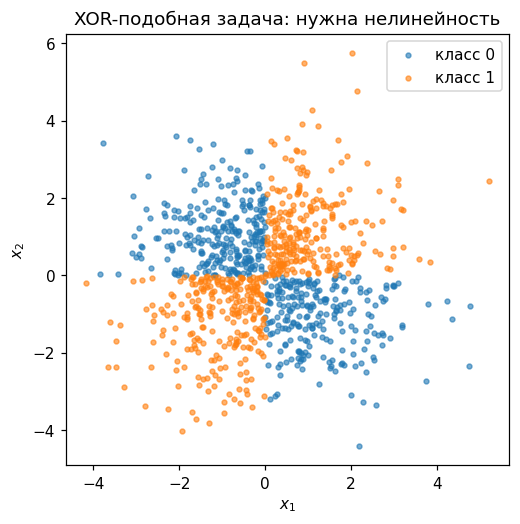

In [25]:
def make_data(n=1024, seed=0):
    g = torch.Generator().manual_seed(seed)
    X = torch.randn(n, 2, generator=g) * 1.4
    # XOR-подобная метка: знаки совпадают -> 0, разные -> 1
    y = ((X[:, 0] * X[:, 1] > 0).long())
    return X, y

X, y = make_data()
print('X:', tuple(X.shape), '| классы:', torch.bincount(y).tolist())

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.scatter(X[y == 0, 0], X[y == 0, 1], s=10, label='класс 0', alpha=0.6)
ax.scatter(X[y == 1, 0], X[y == 1, 1], s=10, label='класс 1', alpha=0.6)
ax.set(xlabel='$x_1$', ylabel='$x_2$', title='XOR-подобная задача: нужна нелинейность')
ax.legend(); plt.show()

In [26]:
# train-функция: одна эпоха = forward -> backward -> step
def train_model(opt_name, lr, epochs=60, batch_size=128, weight_decay=0.0, seed=0, h=32, verbose=False):
    torch.manual_seed(seed)
    X, y = make_data(seed=123)
    n = len(X)
    n_val = n // 5
    Xtr, ytr, Xval, yval = X[:-n_val], y[:-n_val], X[-n_val:], y[-n_val:]

    loader = DataLoader(
        TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True,
        num_workers=0, pin_memory=(device.type == 'cuda'),
    )
    Xval_d, yval_d = Xval.to(device), yval.to(device)

    model = make_model(h=h).to(device)
    crit = nn.CrossEntropyLoss()

    if opt_name == 'sgd':
        opt = torch.optim.SGD(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif opt_name == 'momentum':
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    elif opt_name == 'nesterov':
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, nesterov=True, weight_decay=weight_decay)
    elif opt_name == 'rmsprop':
        opt = torch.optim.RMSprop(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif opt_name == 'adam':
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif opt_name == 'adamw':
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif opt_name == 'nadam':
        opt = torch.optim.NAdam(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        raise ValueError(opt_name)

    hist = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    for ep in range(epochs):
        model.train()
        run = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()
            run += loss.item() * len(xb)
        model.eval()
        with torch.no_grad():
            out = model(Xval_d)
            vl = crit(out, yval_d).item()
            va = (out.argmax(1) == yval_d).float().mean().item()
        hist['train_loss'].append(run / len(Xtr))
        hist['val_loss'].append(vl)
        hist['val_acc'].append(va)
        if verbose and (ep + 1) % 20 == 0:
            print(f'  ep {ep+1:>3}: train={run/len(Xtr):.4f} val={vl:.4f} acc={va:.3f}')
    return hist, model

print('train_model готова. Устройство:', device)

train_model готова. Устройство: cuda


## 7.2. Кто сходится быстрее при одинаковом числе эпох

Обучим одну и ту же сеть разными оптимизаторами с разумными для каждого `lr` и сравним кривые **val loss**.

Здесь видна типичная картина: адаптивные методы (Adam/AdamW/NAdam/RMSprop) **очень быстро выходят на плато** — в первые 10–20 эпох loss падает почти вертикально. Momentum и Nesterov стартуют медленнее, но к концу догоняют и часто дают лучший финальный loss. Чистый SGD с одним и тем же `lr` заметно отстаёт — ему критично нужен свой масштаб шага (см. следующий раздел).

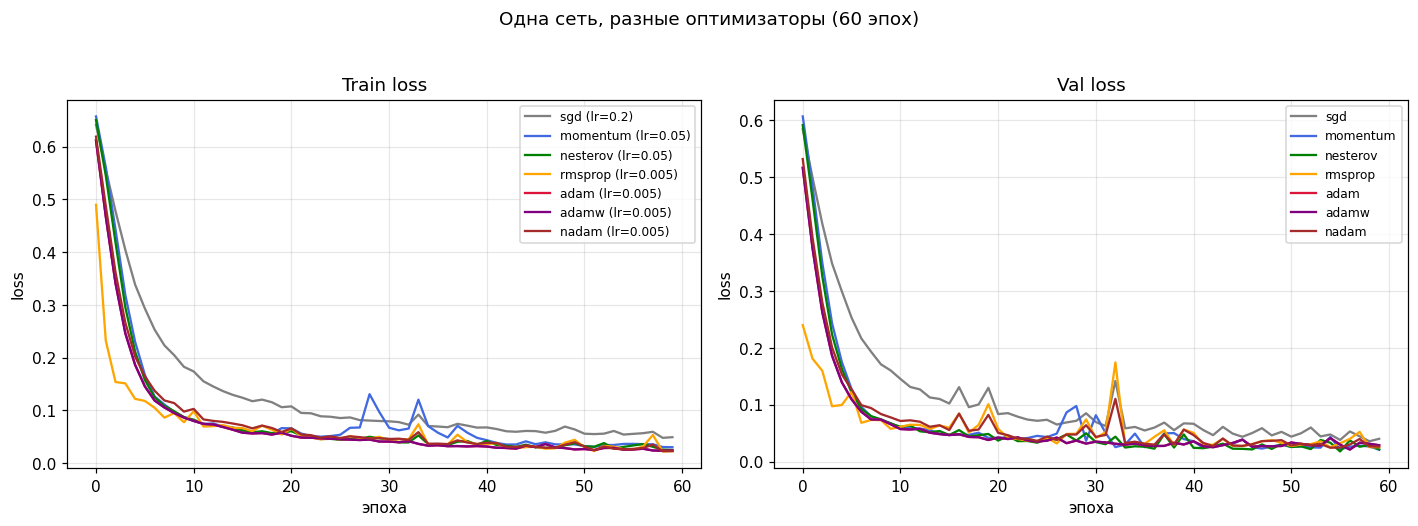

Финальный val loss:
   momentum: 0.0210   (acc 0.995)
   nesterov: 0.0214   (acc 0.985)
    rmsprop: 0.0254   (acc 0.985)
      nadam: 0.0264   (acc 0.985)
       adam: 0.0288   (acc 0.985)
      adamw: 0.0288   (acc 0.985)
        sgd: 0.0402   (acc 0.985)


In [27]:
configs = [
    ('sgd', 0.2, 'gray'),
    ('momentum', 0.05, 'royalblue'),
    ('nesterov', 0.05, 'green'),
    ('rmsprop', 0.005, 'orange'),
    ('adam', 0.005, 'crimson'),
    ('adamw', 0.005, 'purple'),
    ('nadam', 0.005, 'brown'),
]
hists = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for name, lr, c in configs:
    hist, _ = train_model(name, lr, epochs=60, seed=0)
    hists[name] = hist
    axes[0].plot(hist['train_loss'], color=c, label=f'{name} (lr={lr})')
    axes[1].plot(hist['val_loss'], color=c, label=f'{name}')
axes[0].set(title='Train loss', xlabel='эпоха', ylabel='loss'); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].set(title='Val loss', xlabel='эпоха', ylabel='loss'); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.suptitle('Одна сеть, разные оптимизаторы (60 эпох)', y=1.03)
plt.tight_layout(); plt.show()

print('Финальный val loss:')
for name, hist in sorted(hists.items(), key=lambda kv: kv[1]['val_loss'][-1]):
    print(f'  {name:>9}: {hist["val_loss"][-1]:.4f}   (acc {hist["val_acc"][-1]:.3f})')

## 7.3. Честное сравнение: маленький подбор learning rate

Сравнивать «в лоб» нечестно: каждому оптимизатору нужен свой `lr`. Сделаем небольшой перебор по сетке и возьмём **лучший** результат для каждого — тогда картина объективнее.

In [28]:
lr_grid = [0.1, 0.03, 0.01, 0.003, 0.001]
best = {}
for name in ['sgd', 'momentum', 'nesterov', 'rmsprop', 'adam', 'adamw', 'nadam']:
    best_loss, best_lr = np.inf, None
    for lr in lr_grid:
        hist, _ = train_model(name, lr, epochs=50, seed=7)
        fl = hist['val_loss'][-1]
        if fl < best_loss:
            best_loss, best_lr = fl, lr
    best[name] = (best_loss, best_lr)
    print(f'{name:>9}: лучший val loss = {best_loss:.4f}  при lr = {best_lr}')

      sgd: лучший val loss = 0.0701  при lr = 0.1
 momentum: лучший val loss = 0.0311  при lr = 0.03
 nesterov: лучший val loss = 0.0335  при lr = 0.03
  rmsprop: лучший val loss = 0.0555  при lr = 0.001
     adam: лучший val loss = 0.0229  при lr = 0.01
    adamw: лучший val loss = 0.0229  при lr = 0.01
    nadam: лучший val loss = 0.0458  при lr = 0.003


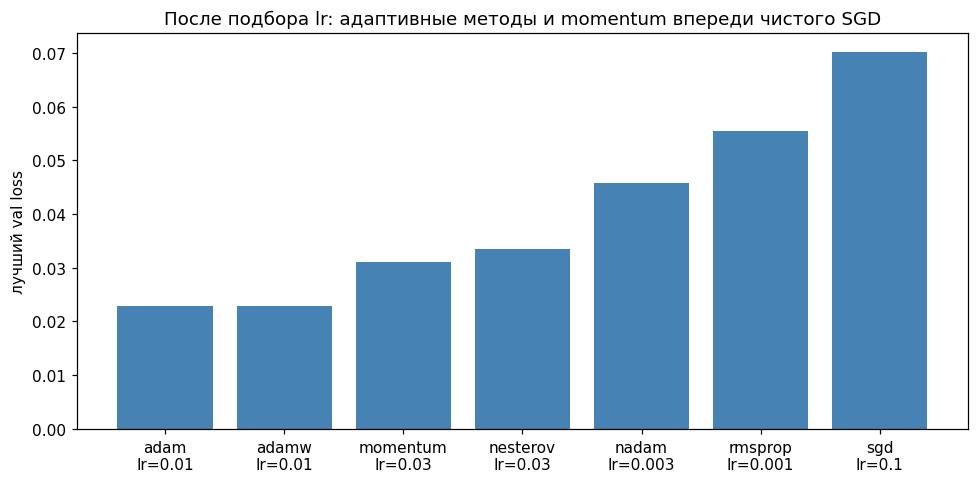

In [29]:
names = ['sgd', 'momentum', 'nesterov', 'rmsprop', 'adam', 'adamw', 'nadam']
losses = [best[n][0] for n in names]
lrs = [best[n][1] for n in names]
order = np.argsort(losses)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(range(len(names)), [losses[i] for i in order], color='steelblue')
ax.set_xticks(range(len(names)))
ax.set_xticklabels([f'{names[i]}\nlr={lrs[i]}' for i in order])
ax.set_ylabel('лучший val loss')
ax.set_title('После подбора lr: адаптивные методы и momentum впереди чистого SGD')
plt.tight_layout(); plt.show()

## 7.4. Анимация: как сеть учит границу решения

Посмотрим на сам процесс: каждый кадр — одна эпоха. Warm-цветные точки — обучающая выборка, фон — предсказанная вероятность класса 1, чёрная линия — граница решения $p=0.5$.

Сравните, как Adam «вырезает» границу за считанные эпохи, а SGD строит её постепенно.

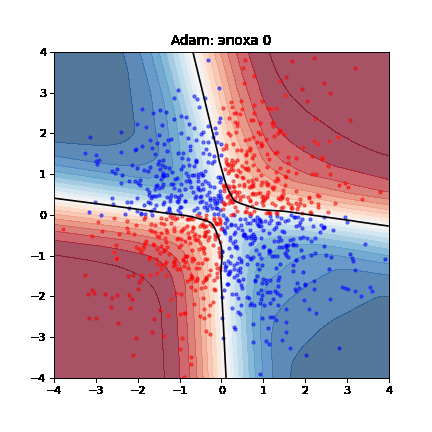

In [30]:
def train_frames(opt_name, lr, epochs=40, seed=0):
    torch.manual_seed(seed)
    X, y = make_data(seed=123)
    loader = DataLoader(TensorDataset(X, y), batch_size=128, shuffle=True, num_workers=0)
    model = make_model(h=32).to(device)
    crit = nn.CrossEntropyLoss()
    opt = {'sgd': lambda p: torch.optim.SGD(p, lr=lr),
           'momentum': lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9),
           'adam': lambda p: torch.optim.Adam(p, lr=lr)}[opt_name](model.parameters())
    frames = []
    xx = np.linspace(-4, 4, 100); yy = np.linspace(-4, 4, 100)
    XX, YY = np.meshgrid(xx, yy)
    grid_pts = torch.tensor(np.stack([XX.ravel(), YY.ravel()], 1), dtype=torch.float32).to(device)
    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = crit(model(xb), yb); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            p = torch.softmax(model(grid_pts), 1)[:, 1].cpu().numpy().reshape(XX.shape)
        frames.append(p)
    return frames, X.numpy(), y.numpy()

frames, Xn, yn = train_frames('adam', 0.01, epochs=24)

# Соберём анимацию границы решения и сохраним её компактным GIF.
xx = np.linspace(-4, 4, 100)
fig, ax = plt.subplots(figsize=(5.4, 5.4))
def draw_frame(i):
    ax.clear()
    ax.contourf(xx, xx, frames[i], levels=20, cmap='RdBu_r', alpha=0.7)
    ax.scatter(Xn[yn == 0, 0], Xn[yn == 0, 1], s=8, color='blue', alpha=0.5)
    ax.scatter(Xn[yn == 1, 0], Xn[yn == 1, 1], s=8, color='red', alpha=0.5)
    ax.contour(xx, xx, frames[i], levels=[0.5], colors='k')
    ax.set_title(f'Adam: эпоха {i}')
    ax.set(xlim=(-4, 4), ylim=(-4, 4))
anim = animation.FuncAnimation(fig, draw_frame, frames=len(frames), interval=140)
show_anim(anim)

## 7.5. Интерактив: покрутите batch size и learning rate

Выберите оптимизатор и параметры и посмотрите, как меняется кривая обучения. Наблюдения, которые стоит проверить руками:

- у **Adam** почти любой разумный `lr` работает — это его главный практический плюс;
- у **SGD** слишком большой `lr` расходится (loss уходит в `nan`/вверх);
- **маленький батч** шумит: train-loss пилит, но часто обобщает не хуже;
- **Momentum** позволяет взять `lr` побольше, чем чистый SGD.

In [31]:
def run_interactive(opt_name='adam', lr=0.01, batch_size=128, weight_decay=0.0, epochs=40):
    torch.manual_seed(0)
    X, y = make_data(seed=123)
    n_val = len(X) // 5
    Xtr, ytr, Xval, yval = X[:-n_val], y[:-n_val], X[-n_val:], y[-n_val:]
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True, num_workers=0)
    model = make_model(h=32).to(device)
    crit = nn.CrossEntropyLoss()
    maker = {
        'sgd': lambda p: torch.optim.SGD(p, lr=lr, weight_decay=weight_decay),
        'momentum': lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9, weight_decay=weight_decay),
        'nesterov': lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9, nesterov=True, weight_decay=weight_decay),
        'rmsprop': lambda p: torch.optim.RMSprop(p, lr=lr, weight_decay=weight_decay),
        'adam': lambda p: torch.optim.Adam(p, lr=lr, weight_decay=weight_decay),
        'adamw': lambda p: torch.optim.AdamW(p, lr=lr, weight_decay=weight_decay),
        'nadam': lambda p: torch.optim.NAdam(p, lr=lr, weight_decay=weight_decay),
    }[opt_name](model.parameters())
    tr, va = [], []
    for ep in range(epochs):
        model.train(); run = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            maker.zero_grad(); loss = crit(model(xb), yb); loss.backward(); maker.step()
            run += loss.item() * len(xb)
        model.eval()
        with torch.no_grad():
            vl = crit(model(Xval.to(device)), yval.to(device)).item()
        tr.append(run / len(Xtr)); va.append(vl)
    plt.figure(figsize=(7, 4))
    plt.plot(tr, label='train'); plt.plot(va, label='val')
    plt.yscale('log'); plt.xlabel('эпоха'); plt.ylabel('loss (log)'); plt.legend(); plt.grid(alpha=0.3)
    plt.title(f'{opt_name} | lr={lr} | batch={batch_size} | wd={weight_decay}')
    plt.show()

interact(run_interactive,
         opt_name=widgets.Dropdown(options=['sgd', 'momentum', 'nesterov', 'rmsprop', 'adam', 'adamw', 'nadam'], value='adam'),
         lr=widgets.Dropdown(options=[0.1, 0.03, 0.01, 0.003, 0.001], value=0.01),
         batch_size=widgets.Dropdown(options=[16, 32, 64, 128, 256], value=128),
         weight_decay=widgets.Dropdown(options=[0.0, 1e-4, 1e-2, 1e-1], value=0.0),
         epochs=widgets.IntSlider(value=40, min=10, max=80, step=10))

interactive(children=(Dropdown(description='opt_name', index=4, options=('sgd', 'momentum', 'nesterov', 'rmspr…

<function __main__.run_interactive(opt_name='adam', lr=0.01, batch_size=128, weight_decay=0.0, epochs=40)>

---
# Часть 8. Тонкости, которые отличают «работает» от «работает хорошо»

## 8.1. Learning rate schedule: зачем менять `lr` по ходу

Постоянный `lr` — компромисс: большой нужен вначале, маленький — в конце. Расписания (schedules) решают это:

| Schedule | Формула / идея | Когда |
|---|---|---|
| **Step decay** | снижаем `lr` в $k$ раз каждые $N$ эпох | классические CNN |
| **Cosine annealing** | плавно по косинусу до почти нуля | современный дефолт для трансформеров/CV |
| **Warmup + cosine** | сначала разогрев, потом затухание | BERT/GPT, большие батчи |
| **ReduceLROnPlateau** | снижаем, когда val-loss перестал падать | когда не хочется думать |

**Правило:** Adam хорошо работает с постоянным `lr`, но связка *warmup + cosine* почти всегда даёт лучшее качество. В PyTorch это `torch.optim.lr_scheduler`.

**Аналогия.** Learning rate schedule — это *как водитель жмёт на газ*: разгон на старте, крейсерская скорость, мягкое торможение у цели.

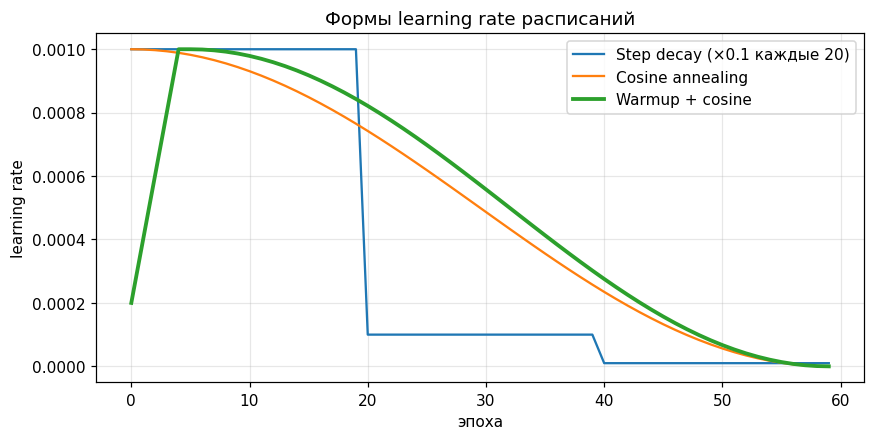

In [32]:
# Сравним три расписания по форме кривой lr.
epochs = 60
fig, ax = plt.subplots(figsize=(9, 4.2))
lr0 = 1e-3
# step decay: x0.1 каждые 20 эпох
step_lrs = [lr0 * (0.1 ** (ep // 20)) for ep in range(epochs)]
# cosine annealing
cos_lrs = [0.5 * lr0 * (1 + np.cos(np.pi * ep / (epochs - 1))) for ep in range(epochs)]
# warmup (5 эпох) + cosine
warm, warm_lrs = 5, []
for ep in range(epochs):
    if ep < warm:
        warm_lrs.append(lr0 * (ep + 1) / warm)
    else:
        warm_lrs.append(0.5 * lr0 * (1 + np.cos(np.pi * (ep - warm) / (epochs - warm - 1))))
ax.plot(step_lrs, label='Step decay (×0.1 каждые 20)')
ax.plot(cos_lrs, label='Cosine annealing')
ax.plot(warm_lrs, label='Warmup + cosine', lw=2.5)
ax.set(xlabel='эпоха', ylabel='learning rate', title='Формы learning rate расписаний'); ax.legend(); ax.grid(alpha=0.3)
plt.show()

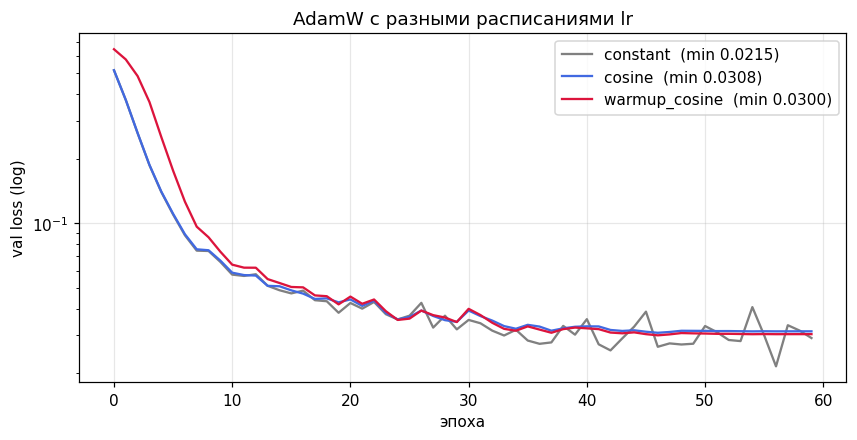

In [33]:
# Реально обучим и сравним: постоянный lr vs cosine vs warmup+cosine (на AdamW).
def train_with_schedule(kind, epochs=60, lr0=5e-3, seed=0):
    torch.manual_seed(seed)
    X, y = make_data(seed=123)
    n_val = len(X) // 5
    Xtr, ytr, Xval, yval = X[:-n_val], y[:-n_val], X[-n_val:], y[-n_val:]
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=128, shuffle=True, num_workers=0)
    model = make_model(h=32).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr0)
    if kind == 'constant':
        sched = None
    elif kind == 'cosine':
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    elif kind == 'warmup_cosine':
        sched = torch.optim.lr_scheduler.LambdaLR(
            opt, lambda ep: (ep + 1) / 5 if ep < 5 else 0.5 * (1 + np.cos(np.pi * (ep - 5) / (epochs - 5)))
        )
    crit = nn.CrossEntropyLoss(); val = []
    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = crit(model(xb), yb); loss.backward(); opt.step()
        if sched: sched.step()
        model.eval()
        with torch.no_grad():
            val.append(crit(model(Xval.to(device)), yval.to(device)).item())
    return val

fig, ax = plt.subplots(figsize=(9, 4.2))
for kind, c in [('constant', 'gray'), ('cosine', 'royalblue'), ('warmup_cosine', 'crimson')]:
    v = train_with_schedule(kind)
    ax.plot(v, color=c, label=f'{kind}  (min {min(v):.4f})')
ax.set_yscale('log'); ax.set(xlabel='эпоха', ylabel='val loss (log)'); ax.legend(); ax.grid(alpha=0.3)
ax.set_title('AdamW с разными расписаниями lr')
plt.show()

## 8.2. Weight decay в реальной задаче: Adam vs AdamW

Проверим на практике тонкость из раздела 3.5. У `torch.optim.Adam` параметр `weight_decay` — это **L2 внутри градиента** (штраф проходит через адаптивное деление на $\sqrt{v}$), а у `torch.optim.AdamW` — **честный decoupled decay**.

Обратите особое внимание на строки `adam, wd=0.01` и `adamw, wd=0.01`: при одинаковом `weight_decay` обычный Adam регуляризует **гораздо агрессивнее** (и часто во вред), потому что штраф делится на маленький адаптивный масштаб. AdamW делает ровно то, что задумано.

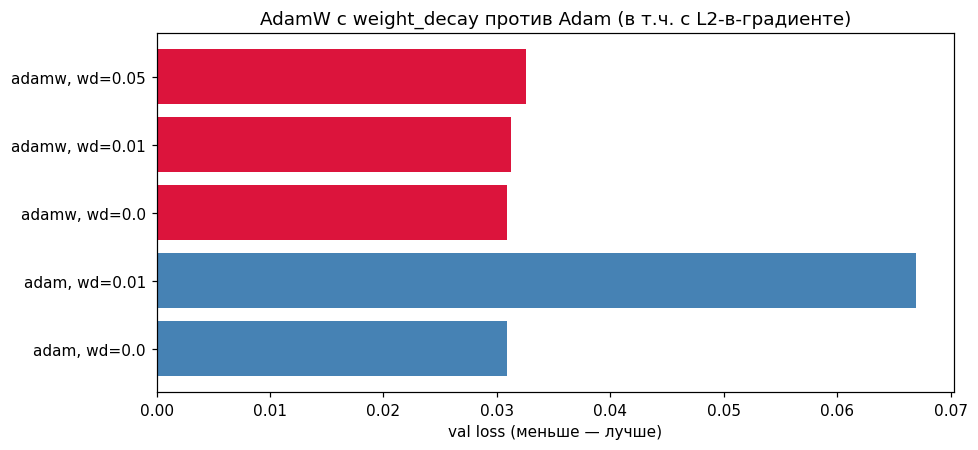

        adam, wd=0.0: 0.0309
       adam, wd=0.01: 0.0670
       adamw, wd=0.0: 0.0309
      adamw, wd=0.01: 0.0312
      adamw, wd=0.05: 0.0325


In [34]:
res = {}
for name, wd in [('adam', 0.0), ('adam', 1e-2), ('adamw', 0.0), ('adamw', 1e-2), ('adamw', 5e-2)]:
    hist, _ = train_model(name, 3e-3, epochs=60, seed=3, weight_decay=wd)
    res[f'{name}, wd={wd}'] = hist['val_loss'][-1]

fig, ax = plt.subplots(figsize=(9, 4.2))
labels = list(res.keys()); vals = list(res.values())
ax.barh(labels, vals, color=['crimson' if 'adamw' in l else 'steelblue' for l in labels])
ax.set_xlabel('val loss (меньше — лучше)')
ax.set_title('AdamW с weight_decay против Adam (в т.ч. с L2-в-градиенте)')
plt.tight_layout(); plt.show()
for k, v in res.items():
    print(f'  {k:>18}: {v:.4f}')

## 8.3. Седловые точки: где momentum действительно незаменим

В настоящих нейросетях критические точки — это чаще не «ямы», а **сёдла**: вдоль одних направлений функция растёт, вдоль других — падает. Чистый SGD у сёдла может застрять надолго; momentum и шум выводят из него.

Возьмём функцию $f = w_1^2 - w_2^2$ (седло в нуле) и стартуем точно на нём со слабым шумом.

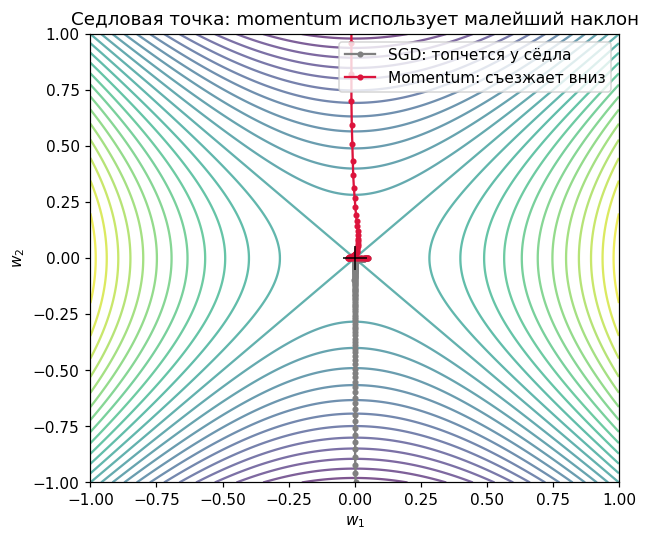

In [35]:
def f_saddle(w):
    return w[..., 0] ** 2 - w[..., 1] ** 2

def g_saddle(w):
    return np.stack([2 * w[..., 0], -2 * w[..., 1]], -1)

np.random.seed(0)
g_saddle_noisy = lambda w: g_saddle(w) + 0.02 * np.random.randn(*w.shape)
p_sgd_s = run_optimizer('sgd', g_saddle_noisy, [0.05, 0.0], 200, lr=0.02)
p_mom_s = run_optimizer('momentum', g_saddle_noisy, [0.05, 0.0], 200, lr=0.02, beta=0.9)

fig, ax = plt.subplots(figsize=(6.2, 5.4))
draw_contours(ax, f_saddle, (-1, 1), (-1, 1), nlev=25)
ax.plot(*p_sgd_s[-1], 'X', color='gray', ms=12)
ax.plot(p_sgd_s[:, 0], p_sgd_s[:, 1], '-o', color='gray', ms=3, label='SGD: топчется у сёдла')
ax.plot(p_mom_s[:, 0], p_mom_s[:, 1], '-o', color='crimson', ms=3, label='Momentum: съезжает вниз')
ax.plot(0, 0, 'k+', ms=16)
ax.legend(); ax.set_title('Седловая точка: momentum использует малейший наклон')
plt.show()

## 8.4. Интерактив: траектория по любому ландшафту

Соберите свой двумерный ландшафт (песочница) и запустите на нём оптимизатор. Это хороший способ «пощупать» моменты и адаптивность.

In [36]:
def live_landscape(kind='bowl', kappa=8.0, opt_name='adam', lr=0.1, beta=0.9, steps=120):
    if kind == 'bowl':
        f = lambda w: bowl(w, kappa); g = lambda w: grad_bowl(w, kappa)
    elif kind == 'saddle':
        f = f_saddle; g = g_saddle
    else:  # noisy
        base = lambda w: bowl(w, kappa)
        bg = lambda w: grad_bowl(w, kappa)
        f = lambda w: base(w) + 0.2 * np.sin(3 * w[..., 0]) * np.cos(3 * w[..., 1])
        g = lambda w: bg(w) + 0.6 * np.stack([np.cos(3 * w[..., 0]) * np.cos(3 * w[..., 1]),
                                              -np.sin(3 * w[..., 0]) * np.sin(3 * w[..., 1])], -1)
    p = run_optimizer(opt_name, g, [-3.0, -2.5], steps=steps, lr=lr, beta=beta)
    fig, ax = plt.subplots(figsize=(5.6, 5.6))
    draw_contours(ax, f, (-4, 2), (-4, 2))
    ax.plot(p[:, 0], p[:, 1], '-o', color='crimson', ms=3)
    ax.plot(*p[-1], 'X', color='k', ms=10)
    ax.set_title(f'{opt_name} | lr={lr} | beta={beta}')
    plt.show()

interact(live_landscape,
         kind=widgets.Dropdown(options=['bowl', 'saddle', 'noisy'], value='bowl'),
         kappa=widgets.FloatSlider(value=8.0, min=1.0, max=30.0, step=1.0),
         opt_name=widgets.Dropdown(options=['sgd', 'momentum', 'nesterov', 'rmsprop', 'adam', 'adamw'], value='adam'),
         lr=widgets.FloatSlider(value=0.1, min=0.01, max=0.5, step=0.01),
         beta=widgets.FloatSlider(value=0.9, min=0.0, max=0.99, step=0.01),
         steps=widgets.IntSlider(value=120, min=20, max=300, step=20))

interactive(children=(Dropdown(description='kind', options=('bowl', 'saddle', 'noisy'), value='bowl'), FloatSl…

<function __main__.live_landscape(kind='bowl', kappa=8.0, opt_name='adam', lr=0.1, beta=0.9, steps=120)>

---
# Часть 9. Итоги и шпаргалка

## 9.1. Все правила одной таблицей

| Оптимизатор | Правило обновления | Память (state) | Когда выбирать |
|---|---|---|---|
| **GD** | $\theta \mathrel{-}= \eta g$ | 0 | теория |
| **SGD** | $\theta \mathrel{-}= \eta g$ (по батчу) | 0 | классические CNN с тюнингом |
| **Momentum** | $v=\beta v+g,\ \theta\mathrel{-}=\eta v$ | 1 | там, где важен зигзаг |
| **Nesterov** | $v=\beta v+\nabla(\theta-\eta\beta v)$ | 1 | почти всегда ≥ momentum |
| **Adagrad** | $s\mathrel{+}=g^2,\ \theta\mathrel{-}=\eta g/\sqrt{s}$ | 1 | разреженные признаки |
| **RMSprop** | $s=\beta s+(1-\beta)g^2,\ \theta\mathrel{-}=\eta g/\sqrt{s}$ | 1 | RNN, нестабильный SGD |
| **Adam** | $m,v$ + bias correction | 2 | **дефолт** |
| **AdamW** | Adam + decoupled decay | 2 | **дефолт для трансформеров** |
| **NAdam** | Adam + Нестеров | 2 | быстрее Adam на старте |
| **RAdam** | Adam + warmup | 2 | нестабильный старт |
| **LAMB** | Adam, шаг ∝ ‖θ‖ | 2 | очень большие батчи |
| **Adafactor** | факторизованный $v$ | ~0.2 | экономия памяти |
| **Lion** | шаг по знаку момента | 1 | скорость, экономия памяти |
| **Sophia** | Adam + кривизна (2-й порядок) | 2 | LLM, ускорение сходимости |

## 9.2. Практический чек-лист

1. **Начните с AdamW**, `lr=1e-3` (для маленьких сетей `3e-4` для больших), `weight_decay=0.01`.
2. **Не сходится / расходится?** Проверьте `lr`: уменьшите в 3–10 раз, добавьте warmup.
3. **Хотите лучший финальный результат на CV?** Попробуйте SGD + Nesterov + cosine.
4. **Стабильность на старте?** Warmup или RAdam.
5. **Не хватает памяти?** Adafactor / Lion, или gradient checkpointing.
6. **Огромные батчи?** LAMB/LARS + линейное масштабирование `lr`.
7. **Всегда сохраняйте `optimizer.state_dict()`** в чекпоинт вместе с весами.
8. **Weight decay ≠ всегда нужен:** для bias и нормировочных слоёв его обычно **отключают** (в PyTorch — раздельные группы параметров).

## 9.3. Главные идеи в трёх строчках

- Оптимизатор превращает **шумный градиент** в **разумный шаг**.
- **Momentum** усредняет направление (инерция): *катимся по дороге, сохраняя движение*.
- **Адаптивность** даёт каждому весу свой шаг: *у каждого свой водитель с круиз-контролем*.
- **Adam = momentum + адаптивность + разгон**, **AdamW** исправляет weight decay.
- Современные вариации (NAdam, RAdam, LAMB, Adafactor, Lion, Sophia) добавляют разогрев, экономию памяти и второй порядок.
- **Правильного `<optim>.weight_decay=` недостаточно:** у Adam это L2-в-градиенте, у AdamW — честный decay; убедитесь, что берёте именно AdamW.

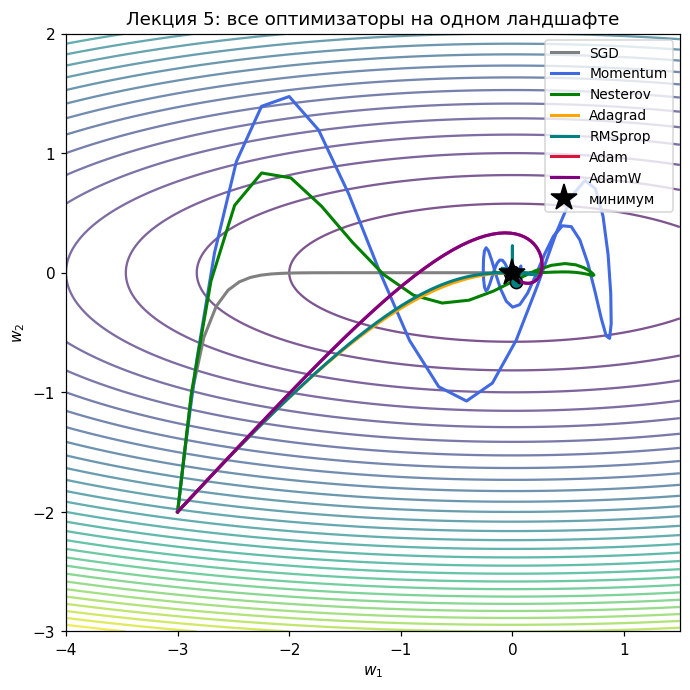

Готово. Теперь вы знаете, что происходит внутри optimizer.step().


In [37]:
# Финальная сводная картинка: пути всех оптимизаторов на одном овраге.
kappa_final = 12.0
f_final = lambda w: bowl(w, kappa_final)
g_final = lambda w: grad_bowl(w, kappa_final)

ops = {
    'SGD': run_optimizer('sgd', g_final, [-3.0, -2.0], 120, lr=0.04),
    'Momentum': run_optimizer('momentum', g_final, [-3.0, -2.0], 120, lr=0.02, beta=0.9),
    'Nesterov': run_optimizer('nesterov', g_final, [-3.0, -2.0], 120, lr=0.022, beta=0.9),
    'Adagrad': run_optimizer('adagrad', g_final, [-3.0, -2.0], 120, lr=0.4),
    'RMSprop': run_optimizer('rmsprop', g_final, [-3.0, -2.0], 120, lr=0.1, beta=0.9),
    'Adam': run_optimizer('adam', g_final, [-3.0, -2.0], 120, lr=0.12),
    'AdamW': run_optimizer('adamw', g_final, [-3.0, -2.0], 120, lr=0.12, wd=0.0),
}
fig, ax = plt.subplots(figsize=(7.2, 7.2))
draw_contours(ax, f_final, (-4, 1.5), (-3, 2), nlev=30)
colors = ['gray', 'royalblue', 'green', 'orange', 'teal', 'crimson', 'purple']
for (name, p), c in zip(ops.items(), colors):
    ax.plot(p[:, 0], p[:, 1], lw=2, color=c, label=name)
    ax.plot(*p[-1], 'o', color=c, ms=8, markeredgecolor='k')
ax.plot(0, 0, 'k*', ms=18, label='минимум')
ax.legend(loc='upper right', fontsize=9)
ax.set_title('Лекция 5: все оптимизаторы на одном ландшафте')
plt.show()
print('Готово. Теперь вы знаете, что происходит внутри optimizer.step().')

## Что попробовать самому

1. **Реализуйте Adam с нуля** и сверьте с `torch.optim.Adam` (у нас уже есть `run_optimizer`, но напишите свой класс).
2. **Добавьте `amsgrad=True`** в свои реализации — это вариант Adam с «максимумом» второго момента; в PyTorch он включён опцией.
3. **Поменяйте `beta2`** в Adam на `0.99` и сравните сходимость — иногда помогает на задачах с шумным градиентом.
4. **Разделите weight decay:** не применяйте его к `bias` и слоям нормировки. В PyTorch — две группы параметров в оптимизаторе.
5. **Сравните Adam и SGD+momentum** на любой CV-задаче (например, CIFAR-10) при равном бюджете времени: кто быстрее достигает целевой точности, а кто — лучше в конце.
6. **Реализуйте Lion** (обновление по знаку момента) поверх наших буферов — там всего пара строк, но непривычная логика.

## Полезные внешние ресурсы

- [Adam: A Method for Stochastic Optimization (Kingma & Ba, 2014)](https://arxiv.org/abs/1412.6980) — оригинал Adam.
- [Decoupled Weight Decay Regularization (Loshchilov & Hutter, 2017)](https://arxiv.org/abs/1711.05101) — AdamW.
- [On the importance of initialization and momentum in deep learning (Sutskever et al., 2013)](https://www.cs.toronto.edu/~fritz/absps/momentum.pdf) — почему momentum работает.
- [Adafactor (Shazeer & Stern, 2018)](https://arxiv.org/abs/1804.04235) — экономия памяти.
- [LAMB (You et al., 2019)](https://arxiv.org/abs/1904.00962) — большие батчи.
- [Symbolic Discovery of Optimization Algorithms (Chen et al., 2023)](https://arxiv.org/abs/2302.06675) — статья про Lion.
- [Sophia (Liu et al., 2023)](https://arxiv.org/abs/2305.14342) — второй порядок для LLM.
- [An overview of gradient descent optimization algorithms (Ruder, 2016)](https://arxiv.org/abs/1609.04747) — отличный обзор.
- [CS231n: Optimization](https://cs231n.github.io/neural-networks-3/) — практические советы по hyperparameter tuning.